# 2.П3. Double-ML

> **Модуль:** Квази-эксперименты · **Блок:** практический · **Время:** 2.5 ч · **Опирается на:** 2.11, 2.10, 2.08

В лекции 2.11 мы разобрали, как устроен Double ML: остатки, кросс-фиттинг, R-learner. В этой практике ответим на другой вопрос: **как получить из наблюдательных данных оценку, которой можно верить, и понять, когда верить нельзя**. Алгоритм напишем сами, а основное время потратим на диагностику, ловушки и проверку.

**Что сделаем на практике**

1. **Посмотрим на наивную оценку** и выпишем, что мы предполагаем о данных.
2. **Напишем Double ML** с интервалом.
3. **Проверим мешающие модели**, перекрытие и зависимость от разбиения.
4. **Попадём в ловушки** выбора признаков.
5. **Разберём бинарное воздействие:** отправлять ли бонус (IRM, ATE, ATT).
6. **Разберём непрерывное воздействие:** какой размер бонуса (наклон и кривая отклика).
7. **Сверимся с библиотекой** `DoubleML`.
8. **Оценим чувствительность** к скрытым конфаундерам.
9. **Решим, кому и сколько** платить, глядя на прибыль.
10. **Откроем случайную группу** и проверим всё, что сделали.
11. **Примем решение** и запишем регламент.

Главный вывод практики: Double ML убирает только то смещение, которое вы ему показали. За всё остальное отвечают граф, диагностика и случайные данные.

## 0. Подготовка

### Библиотеки

Кроме стандартных библиотек нужны `lightgbm` и `doubleml`. В Colab поставьте их командой `!pip install -q lightgbm doubleml`.

In [1]:
import warnings
from pathlib import Path
from urllib.parse import quote

import doubleml as dml
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier, LGBMRegressor
from matplotlib.patches import FancyBboxPatch
from scipy import stats
from sklearn.base import clone, is_classifier
from sklearn.metrics import brier_score_loss, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold, KFold

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F"
PURPLE, ORANGE = "#8172B3", "#DD8452"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

### Легенда

Онлайн-сервис полгода возвращал спящих пользователей: тех, кто не заказывал 30 дней и больше. Раз в месяц CRM-правило решало, кому отправить бонус на следующий заказ и какого размера. Бонус списывается, только если пользователь сделал заказ. Команда хочет понять, окупается ли программа и как её менять.

Отдельного A/B-теста не было, но четверть базы CRM не трогала: там отправка и размер бонуса случайны. Эти данные лежат в отдельном файле, и **мы откроем его только в разделе 10**. Так мы окажемся в положении аналитика, у которого есть только наблюдательные данные, а потом узнаем, насколько близко подошли.

| Столбец | Что это |
|---|---|
| `user_id`, `campaign` | пользователь и номер кампании. Один пользователь бывает в 1–3 кампаниях |
| `days_since_order`, `orders_total`, `avg_check`, `tenure_days` | давность, число заказов, средний чек, срок с регистрации |
| `promo_share`, `tickets_90d`, `app_installed` | доля заказов с промокодом, обращения в поддержку, есть ли приложение |
| `sent`, `bonus` | отправили ли бонус и его размер, ₽ |
| `opened` | открыл ли письмо с бонусом |
| `returned`, `margin` | сделал ли заказ за 30 дней и маржа с заказов до списания бонуса, ₽ |

**Вопрос.** Почему нельзя просто запустить A/B-тест и не мучиться?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Запустить можно и нужно, но вопрос это не закроет. Тест даст ответ через месяц или два, а решение о бюджете нужно сейчас. Сравнить десяток размеров бонуса и десяток сегментов одним тестом дорого. Полгода логов уже есть, и было бы странно их выбросить. Хороший анализ наблюдательных данных не заменяет тест, а подсказывает, какой тест запускать. К этому мы вернёмся в конце.

</details>

In [2]:
FEATURES = ["campaign", "days_since_order", "orders_total", "avg_check", "tenure_days",
            "promo_share", "tickets_90d", "app_installed"]
N_FOLDS = 5
ALPHA = 0.05
Z = stats.norm.ppf(1 - ALPHA / 2)

# мешающие модели: умеренная сложность, сильная регуляризация листьев
LGBM = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=50, subsample=0.8,
            subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1, random_state=0)
reg_model, clf_model = LGBMRegressor(**LGBM), LGBMClassifier(**LGBM)

REPO_PATH = "2. Квази-эксперименты/Практический блок/03. Double-ML/data/"
BASE_URL = "https://raw.githubusercontent.com/Alberelloo/Hypothesis-Testing-Course/main/"


def load(name: str) -> pd.DataFrame:
    local = Path("data") / name
    return pd.read_csv(local if local.exists() else BASE_URL + quote(REPO_PATH + name))


crm = load("reactivation.csv")
print(crm.shape, f"пользователей: {crm['user_id'].nunique():,}")
print(f"Отправили бонус: {crm['sent'].mean():.1%}, средний бонус {crm.loc[crm['sent'] == 1, 'bonus'].mean():.0f} ₽")
print(f"Вернулись: {crm['returned'].mean():.1%}, строк на пользователя: {len(crm) / crm['user_id'].nunique():.2f}")
crm.head()

(134515, 14) пользователей: 84,058
Отправили бонус: 67.5%, средний бонус 303 ₽
Вернулись: 44.7%, строк на пользователя: 1.60


,user_id,campaign,days_since_order,orders_total,avg_check,tenure_days,promo_share,tickets_90d,app_installed,sent,bonus,opened,returned,margin
0,100000,4,46,9,1600,1112,0.244,0,1,0,0,0,1,265
1,100000,5,74,9,1600,1142,0.244,0,1,1,120,1,1,605
2,100001,5,96,13,1440,860,0.798,1,1,1,320,0,1,1214
3,100002,5,52,18,1360,954,0.495,0,0,0,0,0,0,0
4,100002,6,86,18,1360,984,0.495,0,0,1,220,0,0,0


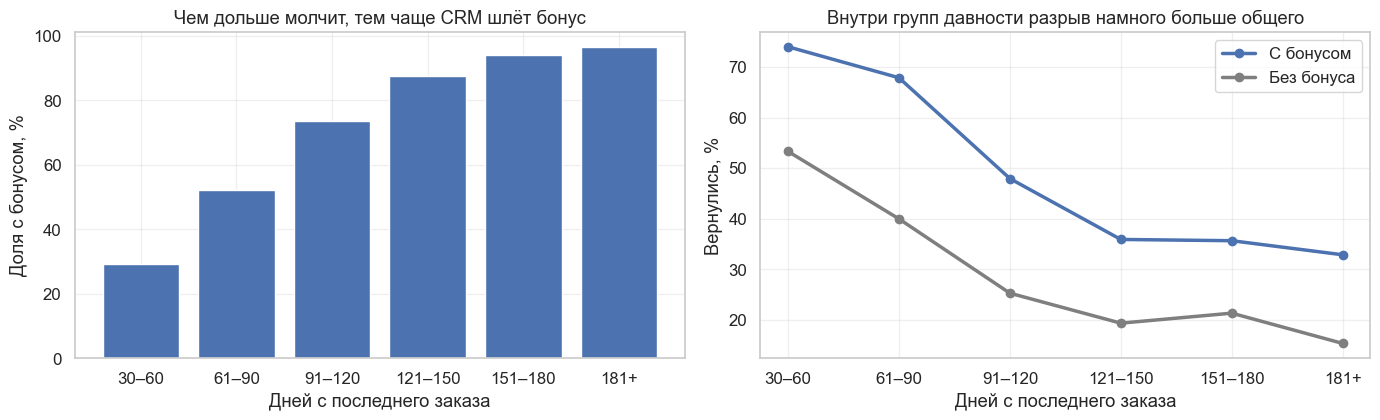

In [3]:
day_bins = pd.cut(crm["days_since_order"], [29, 60, 90, 120, 150, 180, 240],
                  labels=["30–60", "61–90", "91–120", "121–150", "151–180", "181+"])
by_days = crm.groupby([day_bins, "sent"], observed=True)["returned"].mean().unstack()
share_days = crm.groupby(day_bins, observed=True)["sent"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].bar(share_days.index.astype(str), share_days * 100, color=BLUE)
axes[0].set_ylabel("Доля с бонусом, %")
axes[0].set_xlabel("Дней с последнего заказа")
axes[0].set_title("Чем дольше молчит, тем чаще CRM шлёт бонус")
axes[1].plot(by_days.index.astype(str), by_days[1] * 100, marker="o", color=BLUE, lw=2.5, label="С бонусом")
axes[1].plot(by_days.index.astype(str), by_days[0] * 100, marker="o", color=GRAY, lw=2.5, label="Без бонуса")
axes[1].set_ylabel("Вернулись, %")
axes[1].set_xlabel("Дней с последнего заказа")
axes[1].set_title("Внутри групп давности разрыв намного больше общего")
axes[1].legend()
plt.tight_layout()
plt.show()

## 1. Постановка

### Задание 1. Наивная оценка

Самое простое, что может сделать аналитик: сравнить долю вернувшихся с бонусом и без. Реализуйте `naive_by_group(df, by)`: для каждой группы столбца `by` посчитайте число строк `n`, долю отправок `sent_share`, долю вернувшихся с бонусом `returned_1`, без бонуса `returned_0` и разницу `gap`. Если `by=None`, вся таблица считается одной группой.

In [4]:
def naive_by_group(df: pd.DataFrame, by=None) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
def naive_by_group(df: pd.DataFrame, by=None) -> pd.DataFrame:
    key = np.zeros(len(df), dtype=int) if by is None else df[by]
    rows = df.groupby(key, observed=True).apply(lambda g: pd.Series({
        "n": len(g), "sent_share": g["sent"].mean(), "returned_1": g.loc[g["sent"] == 1, "returned"].mean(),
        "returned_0": g.loc[g["sent"] == 0, "returned"].mean()}), include_groups=False)
    return rows.assign(gap=rows["returned_1"] - rows["returned_0"])

In [6]:
# Проверка
naive = naive_by_group(crm).iloc[0]
assert 0.05 < naive["gap"] < 0.12, "Наивная разница должна быть около +8 п.п."
strata = naive_by_group(crm.assign(days=day_bins), "days")
assert (strata["gap"].dropna() > naive["gap"]).sum() >= 4, "Внутри групп давности разница должна быть больше общей"
print(f"Наивная оценка: {naive['gap']:+.3f}")
strata

Наивная оценка: +0.079


,n,sent_share,returned_1,returned_0,gap
days,,,,,
30–60,"21,809.000",0.293,0.740,0.533,0.207
61–90,"30,356.000",0.522,0.679,0.400,0.279
91–120,"33,532.000",0.735,0.479,0.253,0.227
121–150,"32,584.000",0.876,0.359,0.193,0.166
151–180,"12,868.000",0.941,0.356,0.213,0.143
181+,"3,366.000",0.963,0.329,0.153,0.175


Общая разница +7.9 п.п., но внутри групп давности она намного больше: от +14 до +28 п.п. Дело в том, что бонус получают в основном те, кто давно молчит, а они и без бонуса возвращаются реже. Это смещение из-за отбора, и здесь оно занижает эффект.

Стратификация по одному признаку помогает, но признаков много, и зависимости у них нелинейные. Для этого нам и нужен Double ML. Сначала запишем, что мы предполагаем о данных: без этого нельзя решить, какие признаки давать модели.

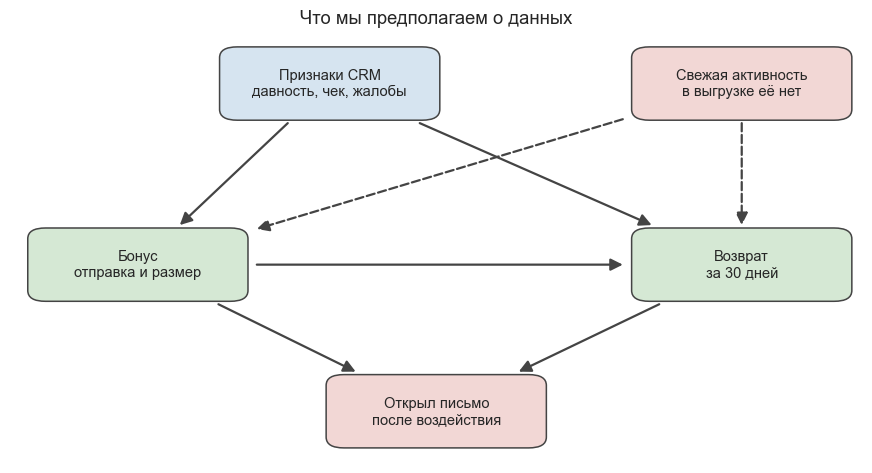

In [7]:
HALF_W, HALF_H = 0.155, 0.085


def box_edge(center, target):
    """Точка на границе прямоугольника узла в направлении на другой узел."""
    dx, dy = target[0] - center[0], target[1] - center[1]
    scale = min(HALF_W / abs(dx) if dx else np.inf, HALF_H / abs(dy) if dy else np.inf) * 1.08
    return center[0] + dx * scale, center[1] + dy * scale


def draw_graph(ax, nodes, edges):
    """Рисует причинный граф: узлы {имя: (x, y, подпись, цвет)}, рёбра (откуда, куда, пунктир)."""
    for start, end, dashed in edges:
        a, b = nodes[start][:2], nodes[end][:2]
        ax.annotate("", xy=box_edge(b, a), xytext=box_edge(a, b), zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.6, ls="--" if dashed else "-",
                                    shrinkA=0, shrinkB=0, mutation_scale=18))
    for x, y, label, color in nodes.values():
        ax.add_patch(FancyBboxPatch((x - HALF_W, y - HALF_H), 2 * HALF_W, 2 * HALF_H, zorder=2, fc=color, ec="#444444",
                                    lw=1.1, boxstyle="round,pad=0,rounding_size=0.025"))
        ax.text(x, y, label, ha="center", va="center", fontsize=10.5, zorder=3)
    ax.set_xlim(0, 1.2)
    ax.set_ylim(0, 1)
    ax.axis("off")


nodes = {
    "X": (0.45, 0.88, "Признаки CRM\nдавность, чек, жалобы", "#D6E4F0"),
    "H": (1.03, 0.88, "Свежая активность\nв выгрузке её нет", "#F2D7D5"),
    "T": (0.18, 0.46, "Бонус\nотправка и размер", "#D5E8D4"),
    "Y": (1.03, 0.46, "Возврат\nза 30 дней", "#D5E8D4"),
    "O": (0.6, 0.12, "Открыл письмо\nпосле воздействия", "#F2D7D5"),
}
edges = [("X", "T", False), ("X", "Y", False), ("H", "T", True), ("H", "Y", True), ("T", "Y", False),
         ("T", "O", False), ("Y", "O", False)]
fig, ax = plt.subplots(figsize=(11, 5.6))
draw_graph(ax, nodes, edges)
ax.set_title("Что мы предполагаем о данных")
plt.show()

**Вопрос.** Какие столбцы таблицы нужно включить в $X$, а какие нельзя? Что на графе остаётся непроверяемым предположением?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Включаем** всё, что известно до кампании и влияет на решение CRM и на возврат: `FEATURES`. Это конфаундеры, их нужно очистить.
* **Не включаем** `opened`. Письмо открывают после отправки, причём чаще те, кто и так собирался вернуться, поэтому на `opened` влияют и $T$, и $Y$. Это коллайдер: если его учесть, появится связь, которой нет. По логике Синелли, Форни и Перла это плохой контроль.
* **Не включаем** `margin`: это исход.
* **Свежая активность** в приложении влияла на решения CRM, но в выгрузку не попала. Это пунктирные стрелки. Если они есть, предположение об отсутствии скрытых конфаундеров нарушено, и никакая ML-модель это не починит. Проверить его по этим данным нельзя, можно только оценить последствия: этим займёмся в разделе 8.

</details>

## 2. Double ML вручную

В лекции 2.11 мы получали только точечную оценку. Здесь нужен ещё и интервал, а для него придётся посмотреть на оценку как на решение уравнения.

Модель та же:

$$
Y_i = \theta T_i + g(X_i) + \varepsilon_i, \qquad T_i = m(X_i) + \nu_i
$$

Обозначим остатки $\tilde{Y}_i = Y_i - \hat{\ell}(X_i)$ и $\tilde{T}_i = T_i - \hat{m}(X_i)$, где $\hat{\ell}$ оценивает $E[Y|X]$, а $\hat{m}$ оценивает $E[T|X]$. Оценка $\hat{\theta}$ — это решение уравнения $\frac{1}{n}\sum \psi_i(\theta) = 0$, где

$$
\psi_i(\theta) = (\tilde{Y}_i - \theta \tilde{T}_i)\, \tilde{T}_i
$$

Это и есть **ортогональная оценка**: ошибки $\hat{\ell}$ и $\hat{m}$ влияют на неё только через произведение, поэтому первая производная по мешающим функциям равна нулю. Дисперсия получается как у любой оценки такого типа:

$$
\hat{\theta} = \frac{\sum \tilde{Y}_i \tilde{T}_i}{\sum \tilde{T}_i^2}, \qquad
\widehat{SE} = \frac{1}{\hat{J}} \sqrt{\frac{1}{n^2} \sum \psi_i(\hat{\theta})^2}, \qquad
\hat{J} = \frac{1}{n}\sum \tilde{T}_i^2
$$

Один пользователь встречается в нескольких кампаниях. Чтобы его строки не попадали одновременно в обучение и в проверку, фолды будем строить по `user_id`. Если строки внутри пользователя зависимы, сумму квадратов нужно считать по пользователям: $\sum_g (\sum_{i \in g} \psi_i)^2$. Проверим в разделе 4, важно ли это здесь.

### Задание 2. Кросс-предсказания

Реализуйте `crossfit_predict(model, X, target, folds)`: для каждого фолда обучите копию модели на остальных строках и предскажите текущие. Для классификатора берите вероятность класса 1. `sklearn.base.clone` и `is_classifier` уже импортированы.

In [8]:
def user_folds(df: pd.DataFrame, n_splits: int = N_FOLDS, seed: int = 0) -> list:
    """Разбиение на фолды, при котором все строки пользователя лежат в одном фолде."""
    return list(GroupKFold(n_splits, shuffle=True, random_state=seed).split(df, groups=df["user_id"]))


def crossfit_predict(model, X: pd.DataFrame, target, folds) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [9]:
# @title Решение (нажмите, чтобы раскрыть)
def crossfit_predict(model, X: pd.DataFrame, target, folds) -> np.ndarray:
    target = np.asarray(target)
    pred = np.zeros(len(target), dtype=float)
    for train_idx, valid_idx in folds:
        fitted = clone(model).fit(X.iloc[train_idx], target[train_idx])
        if is_classifier(model):
            pred[valid_idx] = fitted.predict_proba(X.iloc[valid_idx])[:, 1]
        else:
            pred[valid_idx] = fitted.predict(X.iloc[valid_idx])
    return pred

In [10]:
# Проверка: прогноз вне выборки не должен совпадать с целью
folds = user_folds(crm)
assert all(not set(crm["user_id"].iloc[a]) & set(crm["user_id"].iloc[b]) for a, b in folds), "Пользователь попал в оба куска"
m_y = crossfit_predict(reg_model, crm[FEATURES], crm["returned"], folds)
m_t = crossfit_predict(clf_model, crm[FEATURES], crm["sent"], folds)
assert 0.15 < np.mean((crm["returned"] - m_y) ** 2) < 0.25
assert 0 <= m_t.min() and m_t.max() <= 1
print(f"Средний квадрат остатка: Y {np.mean((crm['returned'] - m_y) ** 2):.4f}, T {np.mean((crm['sent'] - m_t) ** 2):.4f}")

Средний квадрат остатка: Y 0.2196, T 0.1525


### Задание 3. Оценка и интервал

Реализуйте `plr_estimate(y, t, m_y, m_t, groups=None)` по формулам выше. Функция возвращает словарь с ключами `theta`, `se`, `low`, `high`. Если переданы `groups`, сумму квадратов считайте по группам.

In [11]:
def plr_estimate(y, t, m_y, m_t, groups=None) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [12]:
# @title Решение (нажмите, чтобы раскрыть)
def plr_estimate(y, t, m_y, m_t, groups=None) -> dict:
    res_y, res_t = np.asarray(y, float) - m_y, np.asarray(t, float) - m_t
    theta = (res_y * res_t).sum() / (res_t ** 2).sum()
    psi = (res_y - theta * res_t) * res_t
    if groups is not None:
        psi = pd.Series(psi).groupby(np.asarray(groups)).sum().to_numpy()
    se = np.sqrt((psi ** 2).sum()) / (res_t ** 2).sum()
    return {"theta": theta, "se": se, "low": theta - Z * se, "high": theta + Z * se}

In [13]:
# Проверка на данных, где ответ известен: эффект 2, конфаундер x
check_rng = np.random.default_rng(3)
x_check = check_rng.normal(size=200_000)
t_check = x_check + check_rng.normal(size=200_000)
y_check = 2 * t_check + 3 * x_check + check_rng.normal(size=200_000)
check = plr_estimate(y_check, t_check, 5 * x_check, x_check)
assert abs(check["theta"] - 2) < 0.02 and 0.002 < check["se"] < 0.004, "Проверьте формулы"

plr_all = plr_estimate(crm["returned"], crm["sent"], m_y, m_t)
print(f"Наивная оценка: {naive['gap']:+.3f}")
print(f"Double ML:      {plr_all['theta']:+.3f} [{plr_all['low']:+.3f}, {plr_all['high']:+.3f}]")

Наивная оценка: +0.079
Double ML:      +0.241 [+0.235, +0.247]


Оценка выросла втрое: с +7.9 до +24.1 п.п. Значит, основная часть смещения действительно шла от наблюдаемых признаков. Интервал очень узкий, но это интервал только для статистической ошибки. Он ничего не говорит о том, правильно ли выбраны признаки и что именно мы оценили. Этим и займёмся дальше.

## 3. Диагностика мешающих моделей

Оценка получена, но верить ей пока рано. Double ML опирается на три вещи, которые можно проверить: модели хоть что-то предсказывают, у каждого наблюдения есть шанс получить любое воздействие, а результат не зависит от случайного разбиения.

### Задание 4. Качество моделей

Реализуйте `nuisance_report(y, t, m_y, m_t)`: верните словарь с `r2_y` ($R^2$ модели исхода), `auc_t` (ROC-AUC модели воздействия), `brier_t` (её оценка Брайера) и `brier_const` (оценка Брайера постоянного прогноза на уровне доли отправок).

In [14]:
def nuisance_report(y, t, m_y, m_t) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [15]:
# @title Решение (нажмите, чтобы раскрыть)
def nuisance_report(y, t, m_y, m_t) -> dict:
    t = np.asarray(t)
    return {"r2_y": r2_score(y, m_y), "auc_t": roc_auc_score(t, m_t), "brier_t": brier_score_loss(t, m_t),
            "brier_const": brier_score_loss(t, np.full(len(t), t.mean()))}

{'r2_y': 0.112, 'auc_t': 0.829, 'brier_t': 0.153, 'brier_const': 0.22}


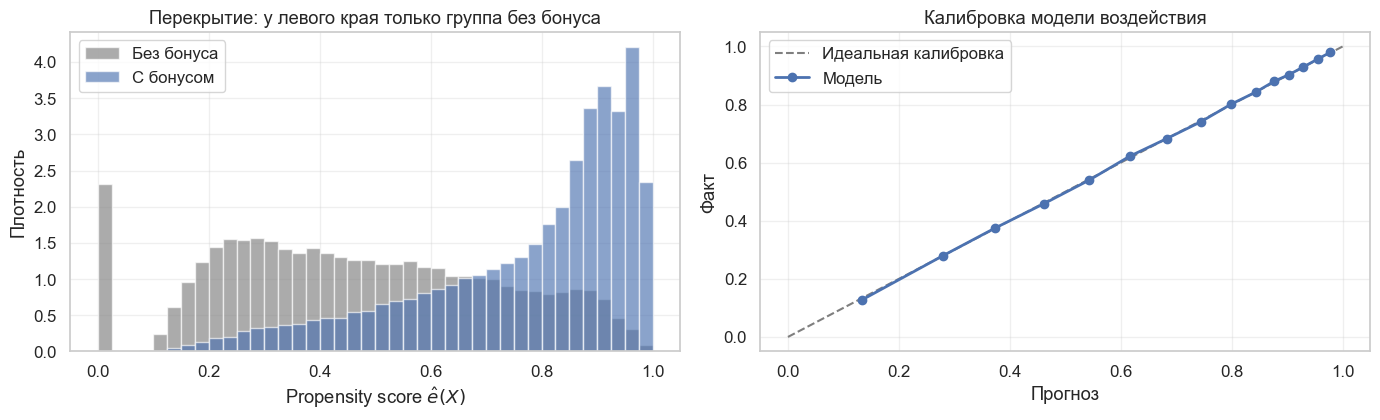

In [16]:
# Проверка
report = nuisance_report(crm["returned"], crm["sent"], m_y, m_t)
assert report["brier_t"] < report["brier_const"], "Модель должна быть лучше константы"
assert report["auc_t"] > 0.7
print({k: round(v, 3) for k, v in report.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
bins = np.linspace(0, 1, 41)
axes[0].hist(m_t[crm["sent"] == 0], bins=bins, alpha=0.65, color=GRAY, density=True, label="Без бонуса")
axes[0].hist(m_t[crm["sent"] == 1], bins=bins, alpha=0.65, color=BLUE, density=True, label="С бонусом")
axes[0].set_xlabel("Propensity score $\\hat{e}(X)$")
axes[0].set_ylabel("Плотность")
axes[0].set_title("Перекрытие: у левого края только группа без бонуса")
axes[0].legend()
quant = pd.qcut(m_t, 15, duplicates="drop")
calib = pd.DataFrame({"pred": m_t, "fact": crm["sent"].to_numpy()}).groupby(quant, observed=True).mean()
axes[1].plot([0, 1], [0, 1], ls="--", color=GRAY, label="Идеальная калибровка")
axes[1].plot(calib["pred"], calib["fact"], marker="o", color=BLUE, lw=2, label="Модель")
axes[1].set_xlabel("Прогноз")
axes[1].set_ylabel("Факт")
axes[1].set_title("Калибровка модели воздействия")
axes[1].legend()
plt.tight_layout()
plt.show()

Что показывают графики:

* **Модель исхода** объясняет 11% дисперсии. Это нормально: возврат одного человека предсказать трудно, а для Double ML важна не точность сама по себе, а то, что модель забирает связь с $X$.
* **Модель воздействия** хорошо откалибрована, AUC 0.83. Слишком хорошая модель была бы тревожным сигналом: AUC около 1 означает, что решение CRM почти полностью определяется $X$, и остаточной вариации $T$ не хватит.
* **Перекрытие.** В середине группы пересекаются, но у левого края виден отдельный пик около нуля, а справа почти все получили бонус. Разберёмся с пиком.

### Задание 5. Перекрытие

Откуда взялся пик у нуля? Реализуйте `overlap_table(df, e, by)`: для каждого значения столбца `by` верните число строк `n`, фактическую долю отправок `sent_share`, минимум и максимум propensity score `e_min`, `e_max`. Постройте таблицу по `tickets_90d`.

In [17]:
def overlap_table(df: pd.DataFrame, e: np.ndarray, by: str) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [18]:
# @title Решение (нажмите, чтобы раскрыть)
def overlap_table(df: pd.DataFrame, e: np.ndarray, by: str) -> pd.DataFrame:
    frame = pd.DataFrame({"key": df[by].to_numpy(), "sent": df["sent"].to_numpy(), "e": e})
    return frame.groupby("key").agg(n=("sent", "size"), sent_share=("sent", "mean"), e_min=("e", "min"), e_max=("e", "max"))

In [19]:
# Проверка
overlap = overlap_table(crm, m_t, "tickets_90d")
assert overlap.loc[overlap.index >= 3, "sent_share"].max() == 0, "Обратите внимание на клиентов с 3+ обращениями"
overlap

,n,sent_share,e_min,e_max
key,,,,
0,77444,0.641,0.083,0.990
1,42759,0.735,0.130,0.992
2,11786,0.815,0.167,0.994
3,2197,0.000,0.002,0.011
4,300,0.000,0.002,0.010
5,27,0.000,0.002,0.008
6,2,0.000,0.003,0.004


При трёх и более обращениях бонус не получил никто: это жёсткое правило CRM «не трогать жалобщиков». Значит, для них условие перекрытия нарушено полностью. Модель не видела ни одного примера с бонусом, и любой прогноз для них был бы экстраполяцией. Обрезка здесь не поможет: данных просто нет.

Правильное решение — честно сузить вопрос: **оцениваем эффект только на пользователях с 0–2 обращениями** и держим в уме, что про остальных данные ничего не говорят. Таких строк меньше 2%, поэтому оценка почти не меняется. Но вывод теперь относится к другой группе, и это нужно писать в отчёте.

In [20]:
MAX_TICKETS = 2
main = crm[crm["tickets_90d"] <= MAX_TICKETS].reset_index(drop=True)
X, y_ret, t_sent, groups = main[FEATURES], main["returned"].to_numpy(), main["sent"].to_numpy(), main["user_id"].to_numpy()

folds = user_folds(main)
m_y = crossfit_predict(reg_model, X, y_ret, folds)
m_t = crossfit_predict(clf_model, X, t_sent, folds)
plr_main = plr_estimate(y_ret, t_sent, m_y, m_t, groups)
print(f"Строк: {len(main):,} из {len(crm):,}. Диапазон propensity score: {m_t.min():.3f}–{m_t.max():.3f}")
print(f"Double ML: {plr_main['theta']:+.3f} [{plr_main['low']:+.3f}, {plr_main['high']:+.3f}]")

Строк: 131,989 из 134,515. Диапазон propensity score: 0.086–0.993
Double ML: +0.241 [+0.235, +0.247]


### Задание 6. Зависимость от разбиения

Результат зависит от случайного разбиения на фолды, и разброс из-за этого не входит в стандартную ошибку. Черножуков и соавторы предлагают повторять кросс-фиттинг и брать среднее или медиану оценок. Реализуйте `split_stability(df, seeds)`: для каждого зерна постройте `user_folds`, получите предсказания и оценку. Верните таблицу со столбцами `seed`, `theta`, `se`.

In [21]:
def split_stability(df: pd.DataFrame, seeds) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [22]:
# @title Решение (нажмите, чтобы раскрыть)
def split_stability(df: pd.DataFrame, seeds) -> pd.DataFrame:
    rows = []
    for seed in seeds:
        current = user_folds(df, seed=seed)
        pred_y = crossfit_predict(reg_model, df[FEATURES], df["returned"], current)
        pred_t = crossfit_predict(clf_model, df[FEATURES], df["sent"], current)
        est = plr_estimate(df["returned"], df["sent"], pred_y, pred_t, df["user_id"])
        rows.append({"seed": seed, "theta": est["theta"], "se": est["se"]})
    return pd.DataFrame(rows)

In [23]:
# Проверка
stability = split_stability(main, range(1, 7))
assert len(stability) == 6 and stability["theta"].std() > 0
print(f"Медиана {stability['theta'].median():+.4f}, размах {stability['theta'].max() - stability['theta'].min():.4f}")
print(f"Разброс по разбиениям {stability['theta'].std():.4f} против стандартной ошибки {stability['se'].mean():.4f}")

Медиана +0.2410, размах 0.0003
Разброс по разбиениям 0.0001 против стандартной ошибки 0.0031


Разброс по разбиениям 0.0001, в 30 раз меньше стандартной ошибки. На таком объёме данных разбиение почти не важно. На небольших данных картина бывает другой, поэтому проверка стоит копейки и остаётся в регламенте. В библиотеке её заменяет параметр `n_rep`.

## 4. Ловушки

Double ML не проверяет, правильно ли выбраны признаки: он честно очистит $T$ и $Y$ от всего, что ему дали. Проверим три решения аналитика, которые в коде выглядят одинаково безобидно.

### Задание 7. Что меняется от выбора признаков и фолдов

Реализуйте `plr_scenario(df, features, folds, cluster=True)`: кросс-предсказания на признаках `features` и оценка `plr_estimate`. Если `cluster=False`, ошибку считайте без группировки. Затем заполните таблицу сценариев.

In [24]:
def plr_scenario(df: pd.DataFrame, features: list, folds, cluster: bool = True) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [25]:
# @title Решение (нажмите, чтобы раскрыть)
def plr_scenario(df: pd.DataFrame, features: list, folds, cluster: bool = True) -> dict:
    pred_y = crossfit_predict(reg_model, df[features], df["returned"], folds)
    pred_t = crossfit_predict(clf_model, df[features], df["sent"], folds)
    return plr_estimate(df["returned"], df["sent"], pred_y, pred_t, df["user_id"] if cluster else None)

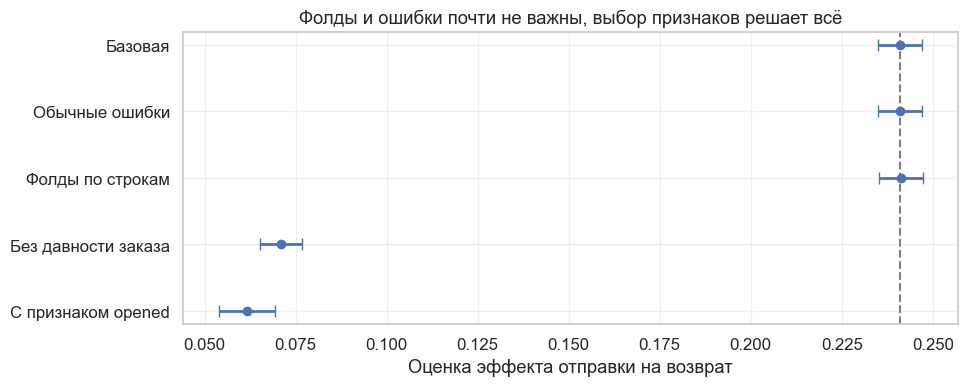

,theta,se,low,high
Базовая,0.241,0.003,0.235,0.247
Обычные ошибки,0.241,0.003,0.235,0.247
Фолды по строкам,0.241,0.003,0.235,0.247
Без давности заказа,0.071,0.003,0.065,0.077
С признаком opened,0.062,0.004,0.054,0.069


In [26]:
row_folds = list(KFold(N_FOLDS, shuffle=True, random_state=0).split(main))
without_days = [f for f in FEATURES if f != "days_since_order"]
traps = pd.DataFrame({
    "Базовая": plr_scenario(main, FEATURES, folds),
    "Обычные ошибки": plr_scenario(main, FEATURES, folds, cluster=False),
    "Фолды по строкам": plr_scenario(main, FEATURES, row_folds),
    "Без давности заказа": plr_scenario(main, without_days, folds),
    "С признаком opened": plr_scenario(main, FEATURES + ["opened"], folds),
}).T

# Проверка
assert traps.loc["С признаком opened", "theta"] < traps.loc["Базовая", "theta"] / 2, "Контроль после воздействия должен обвалить оценку"
assert traps.loc["Без давности заказа", "theta"] < traps.loc["Базовая", "theta"] / 2

fig, ax = plt.subplots(figsize=(10, 3.8))
order = traps.iloc[::-1]
ax.errorbar(order["theta"], order.index, xerr=Z * order["se"], fmt="o", color=BLUE, capsize=4, lw=2)
ax.axvline(traps.loc["Базовая", "theta"], ls="--", color=GRAY)
ax.set_xlabel("Оценка эффекта отправки на возврат")
ax.set_title("Фолды и ошибки почти не важны, выбор признаков решает всё")
plt.show()
traps.round(4)

Что показывает график:

* **Фолды по строкам и обычные ошибки ничего не изменили.** Мы ждали проблему: строки одного пользователя зависимы. Но в оценочной функции перемножаются остатки исхода и воздействия, а остатки воздействия у разных кампаний одного пользователя почти независимы (корреляция 0.005), поэтому и произведения почти не коррелируют. Модели с `min_child_samples=50` к тому же не могут запомнить отдельного человека. Это наблюдение про наши данные, а не общее правило: если бы одно решение CRM распространялось на все кампании пользователя, картина была бы другой. Поэтому фолды по `user_id` мы оставляем: они ничего не стоят.
* **Без давности заказа** оценка падает до +7.1 п.п., почти к наивной. Один потерянный конфаундер отменяет всю работу.
* **С признаком `opened`** оценка падает до +6.2 п.п. Хотя признак добавили, а не убрали, и модель стала точнее. Интервал при этом остаётся узким и ничем не намекает на проблему.

Качество мешающих моделей здесь не поможет: с `opened` $R^2$ модели исхода растёт с 0.11 до 0.20. Поэтому автоматический отбор признаков опасен для Double ML, об этом статья Хюнерманда и соавторов. Решение о том, что идёт в $X$, принимается по графу, а не по метрикам.

## 5. Случай 1: отправлять ли бонус

До сих пор мы оценивали одно число $\theta$ в линейной модели. Но эффект у разных пользователей разный, и тогда $\theta$ — это не средний эффект. Для оценки из регрессии остатков верно:

$$
\theta_{PLR} = \frac{E\big[e(X)(1 - e(X))\, \tau(X)\big]}{E\big[e(X)(1 - e(X))\big]}
$$

Наибольший вес получают наблюдения с propensity score около 0.5, а не те, кто нас интересует. Для бинарного воздействия есть прямая оценка ATE: **interactive regression model (IRM)**. Это та же двойная робастная оценка (AIPW) из лекции 2.10, только с кросс-фиттингом:

$$
\psi_i = \hat{\mu}_1(X_i) - \hat{\mu}_0(X_i) + \frac{T_i (Y_i - \hat{\mu}_1(X_i))}{\hat{e}(X_i)} - \frac{(1 - T_i)(Y_i - \hat{\mu}_0(X_i))}{1 - \hat{e}(X_i)}, \qquad \hat{\tau}_{ATE} = \frac{1}{n} \sum \psi_i
$$

Для эффекта на получивших (ATT) оценка другая. Здесь $p = P(T = 1)$:

$$
\psi_i^{ATT} = \frac{T_i (Y_i - \hat{\mu}_0(X_i))}{p} - \frac{\hat{e}(X_i)}{1 - \hat{e}(X_i)} \cdot \frac{(1 - T_i)(Y_i - \hat{\mu}_0(X_i))}{p}
$$

Функция `arm_predictions` ниже считает $\hat{\mu}_0$ и $\hat{\mu}_1$ на кросс-фиттинге.

### Задание 8. AIPW

Реализуйте `aipw_scores(y, t, mu0, mu1, e)` и `att_scores(y, t, mu0, e)`: они возвращают массивы $\psi_i$. Оценка — среднее, ошибка считается функцией `score_summary`.

In [27]:
def arm_predictions(df: pd.DataFrame, y, t, folds, features=FEATURES) -> tuple:
    """Кросс-предсказания исхода при T = 0 и T = 1: модель обучается только на своей группе."""
    y, t, X_all = np.asarray(y, float), np.asarray(t), df[features]
    mu0, mu1 = np.zeros(len(y)), np.zeros(len(y))
    for train_idx, valid_idx in folds:
        for value, out in [(0, mu0), (1, mu1)]:
            part = train_idx[t[train_idx] == value]
            out[valid_idx] = clone(reg_model).fit(X_all.iloc[part], y[part]).predict(X_all.iloc[valid_idx])
    return mu0, mu1


def score_summary(psi, groups) -> dict:
    """Среднее оценочной функции и ошибка с группировкой по пользователям."""
    center = pd.Series(psi - psi.mean()).groupby(np.asarray(groups)).sum().to_numpy()
    theta, se = psi.mean(), np.sqrt((center ** 2).sum()) / len(psi)
    return {"theta": theta, "se": se, "low": theta - Z * se, "high": theta + Z * se}


def aipw_scores(y, t, mu0, mu1, e) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError


def att_scores(y, t, mu0, e) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [28]:
# @title Решение (нажмите, чтобы раскрыть)
def aipw_scores(y, t, mu0, mu1, e) -> np.ndarray:
    y, t = np.asarray(y, float), np.asarray(t, float)
    return mu1 - mu0 + t * (y - mu1) / e - (1 - t) * (y - mu0) / (1 - e)


def att_scores(y, t, mu0, e) -> np.ndarray:
    y, t = np.asarray(y, float), np.asarray(t, float)
    return (t - (1 - t) * e / (1 - e)) * (y - mu0) / t.mean()

In [29]:
# Проверка: при случайной отправке и точных моделях оценка равна истинному эффекту
check_rng = np.random.default_rng(4)
t_check = check_rng.integers(0, 2, 100_000)
y_check = 1 + 0.5 * t_check + check_rng.normal(size=100_000)
assert abs(aipw_scores(y_check, t_check, np.ones(100_000), np.full(100_000, 1.5), np.full(100_000, 0.5)).mean() - 0.5) < 0.02
assert abs(att_scores(y_check, t_check, np.ones(100_000), np.full(100_000, 0.5)).mean() - 0.5) < 0.02

mu0, mu1 = arm_predictions(main, y_ret, t_sent, folds)
e_hat = np.clip(m_t, 0.01, 0.99)
psi_ate = aipw_scores(y_ret, t_sent, mu0, mu1, e_hat)
psi_att = att_scores(y_ret, t_sent, mu0, e_hat)
estimates = pd.DataFrame({"PLR (веса e(1-e))": plr_main, "ATE (IRM)": score_summary(psi_ate, groups),
                          "ATT": score_summary(psi_att, groups)}).T
estimates.round(4)

,theta,se,low,high
PLR (веса e(1-e)),0.241,0.003,0.235,0.247
ATE (IRM),0.212,0.004,0.205,0.220
ATT,0.197,0.005,0.188,0.206


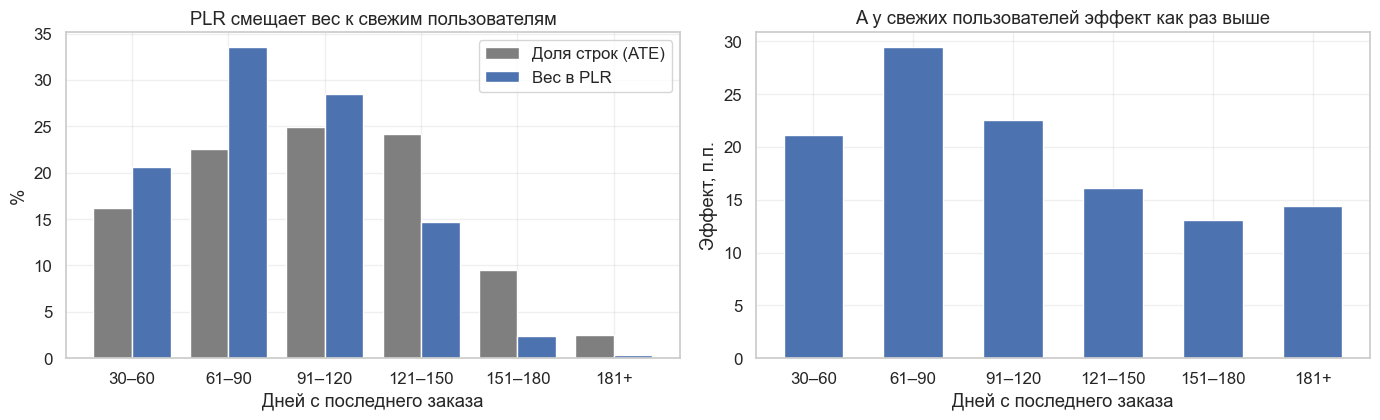

In [30]:
weights = e_hat * (1 - e_hat)
days_group = pd.cut(main["days_since_order"], [29, 60, 90, 120, 150, 180, 240],
                    labels=["30–60", "61–90", "91–120", "121–150", "151–180", "181+"])
weight_table = pd.DataFrame({"psi": psi_ate, "weight": weights, "days": days_group}).groupby("days", observed=True).agg(
    effect=("psi", "mean"), weight=("weight", "sum"), n=("psi", "size"))
weight_table["share_plr"] = weight_table["weight"] / weight_table["weight"].sum()
weight_table["share_all"] = weight_table["n"] / weight_table["n"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
pos = np.arange(len(weight_table))
axes[0].bar(pos - 0.2, weight_table["share_all"] * 100, 0.4, color=GRAY, label="Доля строк (ATE)")
axes[0].bar(pos + 0.2, weight_table["share_plr"] * 100, 0.4, color=BLUE, label="Вес в PLR")
axes[0].set_xticks(pos, weight_table.index.astype(str))
axes[0].set_xlabel("Дней с последнего заказа")
axes[0].set_ylabel("%")
axes[0].set_title("PLR смещает вес к свежим пользователям")
axes[0].legend()
axes[1].bar(pos, weight_table["effect"] * 100, color=BLUE, width=0.6)
axes[1].set_xticks(pos, weight_table.index.astype(str))
axes[1].set_xlabel("Дней с последнего заказа")
axes[1].set_ylabel("Эффект, п.п.")
axes[1].set_title("А у свежих пользователей эффект как раз выше")
plt.tight_layout()
plt.show()

Три числа, три разных вопроса:

| Оценка | Значение | Что отвечает |
|---|---|---|
| PLR | +24.1 п.п. | средний эффект с весами $e(1-e)$. Удобной бизнес-трактовки нет |
| ATE | +21.2 п.п. | что будет, если отправить бонус всем против никому |
| ATT | +19.7 п.п. | что дал бонус тем, кому его реально отправили |

Разница не в шуме, а в том, кого считаем. На графике видно почему: PLR перекладывает вес с давно молчащих пользователей, которым CRM шлёт бонус почти всегда, на группы с долей отправок около половины, а там эффект как раз выше. ATT ниже ATE по той же причине: CRM отправляет бонусы туда, где эффект меньше. Это уже первый намёк на то, что правило выбирает не тех.

Если эффект однороден, все три числа совпадают. Поэтому их расхождение само по себе говорит о неоднородности.

### Задание 9. Переобученный propensity score

В IRM оценка делится на $\hat{e}$ и $1 - \hat{e}$, поэтому модель воздействия здесь важнее, чем в PLR. Обучим намеренно переобученный классификатор `flex_model`. Реализуйте `clip_table(y, t, mu0, mu1, e, clips, groups)`: для каждого порога из `clips` обрежьте $\hat{e}$ до $[c, 1 - c]$ и верните таблицу с `clip`, `theta`, `se`, долей обрезанных строк `share`.

In [31]:
flex_model = LGBMClassifier(n_estimators=400, learning_rate=0.1, num_leaves=255, min_child_samples=2,
                            verbose=-1, n_jobs=-1, random_state=0)
e_flex = crossfit_predict(flex_model, X, t_sent, folds)
print(f"Брайер: обычная модель {brier_score_loss(t_sent, m_t):.4f}, переобученная {brier_score_loss(t_sent, e_flex):.4f}")
print(f"Диапазон переобученной: {e_flex.min():.6f}–{e_flex.max():.6f}")


def clip_table(y, t, mu0, mu1, e, clips, groups) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

Брайер: обычная модель 0.1555, переобученная 0.1637
Диапазон переобученной: 0.001744–0.999967


In [32]:
# @title Решение (нажмите, чтобы раскрыть)
def clip_table(y, t, mu0, mu1, e, clips, groups) -> pd.DataFrame:
    rows = []
    for clip in clips:
        clipped = np.clip(e, clip, 1 - clip)
        est = score_summary(aipw_scores(y, t, mu0, mu1, clipped), groups)
        rows.append({"clip": clip, "theta": est["theta"], "se": est["se"], "share": np.mean(clipped != e)})
    return pd.DataFrame(rows)

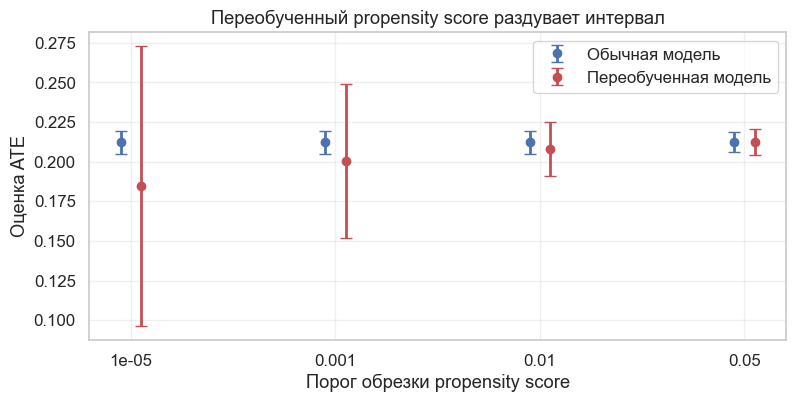

,clip,theta,se,share,model
0,0.000,0.212,0.004,0.000,обычная
1,0.001,0.212,0.004,0.000,обычная
2,0.010,0.212,0.004,0.001,обычная
3,0.050,0.213,0.003,0.117,обычная
0,0.000,0.184,0.045,0.000,переобученная
1,0.001,0.200,0.025,0.009,переобученная
2,0.010,0.208,0.009,0.092,переобученная
3,0.050,0.212,0.004,0.241,переобученная


In [33]:
# Проверка
clips = [1e-5, 0.001, 0.01, 0.05]
clip_good = clip_table(y_ret, t_sent, mu0, mu1, m_t, clips, groups)
clip_flex = clip_table(y_ret, t_sent, mu0, mu1, e_flex, clips, groups)
assert clip_flex["se"].iloc[0] > 3 * clip_good["se"].iloc[0], "Переобученная модель должна раздувать ошибку"

fig, ax = plt.subplots(figsize=(9, 4))
pos = np.arange(len(clips))
ax.errorbar(pos - 0.05, clip_good["theta"], yerr=Z * clip_good["se"], fmt="o", color=BLUE, capsize=4, lw=2, label="Обычная модель")
ax.errorbar(pos + 0.05, clip_flex["theta"], yerr=Z * clip_flex["se"], fmt="o", color=RED, capsize=4, lw=2, label="Переобученная модель")
ax.set_xticks(pos, [str(c) for c in clips])
ax.set_xlabel("Порог обрезки propensity score")
ax.set_ylabel("Оценка ATE")
ax.set_title("Переобученный propensity score раздувает интервал")
ax.legend()
plt.show()
pd.concat([clip_good.assign(model="обычная"), clip_flex.assign(model="переобученная")]).round(4)

С обычной моделью обрезка почти ни на что не влияет. С переобученной ошибка выросла в 12 раз: с 0.004 до 0.045, а точечная оценка ушла на 2.8 п.п. Причём по оценке Брайера модель хуже всего на 5%: 0.164 против 0.156. Но её вероятности доходят до 0.99997, и отдельные строки получают огромные веса.

Обрезка возвращает ошибку к разумной: при пороге 0.05 это 0.004. Но она меняет то, что мы считаем, ведь теперь у 24% строк вес задан порогом, а не данными. Правильное лечение — регуляризовать модель, а обрезку использовать как страховку. Если результат заметно зависит от порога, значит, проблема в модели или в перекрытии.

Для PLR такой проблемы нет: там на $\hat{e}$ ничего не делится. Это ещё одна причина смотреть на обе оценки.

## 6. Случай 2: какой размер бонуса

Теперь вопрос другой: на сколько вырастет возврат, если бонус увеличить. DoorDash разделяет эти два случая так же: фиксированный оффер моделируют как выбор, кому его показать, а настраиваемый размер как непрерывное воздействие. Берём только тех, кому бонус отправили, поэтому $T$ — размер бонуса в сотнях рублей. CRM меняла размер не случайно, но с заметным шумом: один и тот же профиль получал разные бонусы. На этом шуме и держится оценка.

### Задание 10. Эффект 100 рублей

Постройте `sent_rows`, остатки и оценку. Наивный наклон уже посчитан, сравните. Используйте те же `crossfit_predict` и `plr_estimate`, но модель воздействия теперь регрессионная.

In [34]:
sent_rows = main[main["sent"] == 1].reset_index(drop=True)
bonus_h = sent_rows["bonus"].to_numpy() / 100
y_sent = sent_rows["returned"].to_numpy()
naive_slope = np.polyfit(bonus_h, y_sent, 1)[0]

# ВАШ КОД: посчитайте my_sent, mb_sent и bonus_est
my_sent, mb_sent, bonus_est = None, None, None

In [35]:
# @title Решение (нажмите, чтобы раскрыть)
sent_folds = user_folds(sent_rows)
my_sent = crossfit_predict(reg_model, sent_rows[FEATURES], y_sent, sent_folds)
mb_sent = crossfit_predict(reg_model, sent_rows[FEATURES], bonus_h, sent_folds)
bonus_est = plr_estimate(y_sent, bonus_h, my_sent, mb_sent, sent_rows["user_id"])

Наивный наклон на 100 ₽: -0.0708
Double ML:               +0.0400 [+0.0355, +0.0446]
Разброс бонуса: 0.83, остаточный: 0.65


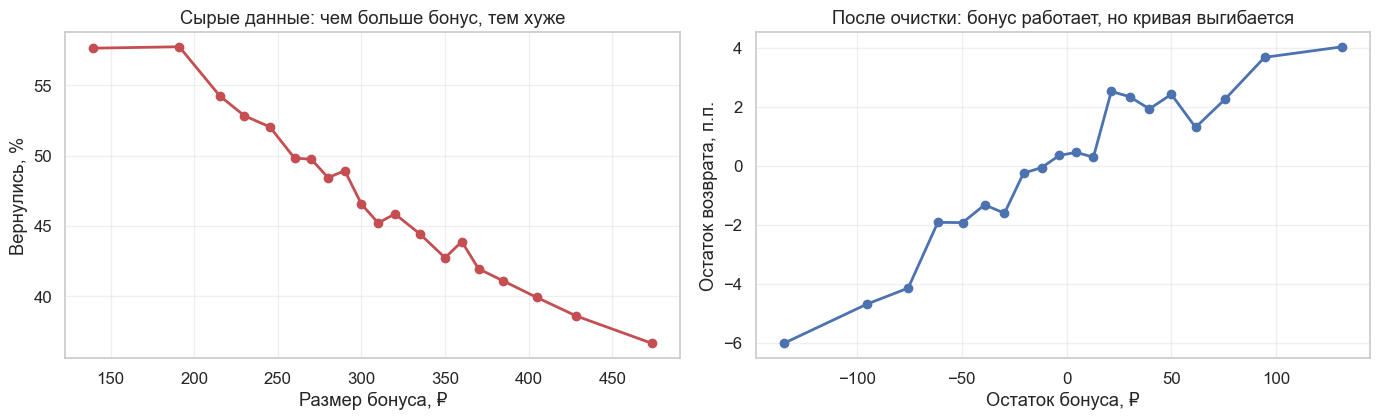

In [36]:
# Проверка
assert naive_slope < 0 < bonus_est["theta"], "Наивный наклон и оценка должны иметь разные знаки"
assert (bonus_h - mb_sent).std() > 0.4, "Нужна остаточная вариация бонуса"
print(f"Наивный наклон на 100 ₽: {naive_slope:+.4f}")
print(f"Double ML:               {bonus_est['theta']:+.4f} [{bonus_est['low']:+.4f}, {bonus_est['high']:+.4f}]")
print(f"Разброс бонуса: {bonus_h.std():.2f}, остаточный: {(bonus_h - mb_sent).std():.2f}")


def binned(x, y, n=20):
    frame = pd.DataFrame({"x": x, "y": y})
    return frame.groupby(pd.qcut(frame["x"], n, duplicates="drop"), observed=True).mean()


fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
raw, res = binned(bonus_h * 100, y_sent), binned((bonus_h - mb_sent) * 100, y_sent - my_sent)
axes[0].plot(raw["x"], raw["y"] * 100, marker="o", color=RED, lw=2)
axes[0].set_xlabel("Размер бонуса, ₽")
axes[0].set_ylabel("Вернулись, %")
axes[0].set_title("Сырые данные: чем больше бонус, тем хуже")
axes[1].plot(res["x"], res["y"] * 100, marker="o", color=BLUE, lw=2)
axes[1].set_xlabel("Остаток бонуса, ₽")
axes[1].set_ylabel("Остаток возврата, п.п.")
axes[1].set_title("После очистки: бонус работает, но кривая выгибается")
plt.tight_layout()
plt.show()

Наивный наклон даже другого знака: каждые 100 ₽ якобы снижают возврат на 7 п.п. Потому что большие бонусы CRM даёт тем, кто давно молчит. Double ML показывает рост на 4 п.п. на 100 ₽.

Обратите внимание на остаточный разброс: 0.65 при общем 0.83. Это и есть та вариация, на которой держится оценка. Если бы CRM назначала бонус строго по формуле, остаток был бы близок к нулю, и оценить эффект было бы нельзя, сколько бы данных ни было.

Но что значит одно число, если отклик нелинеен? $\theta$ здесь — средний наклон с весами $\tilde{T}^2$ в той области, где CRM реально работала. Эффект от 100 до 200 ₽ и от 400 до 500 ₽ он описывает одинаково плохо.

### Задание 11. Кривая отклика

Модель $\theta \cdot T$ линейна по $T$, а график выше нет. Но линейность — это не ограничение метода: она относится к тому, что стоит при $\theta$. Заменим $T$ на несколько базисных функций $B(T)$ и очистим от $X$ каждую из них:

$$
\tilde{Y}_i = \sum_{j} \beta_j \tilde{B}_j(T_i) + \varepsilon_i, \qquad \tilde{B}_j = B_j(T_i) - \hat{E}[B_j(T)|X_i]
$$

Возьмём кусочно-линейный базис с узлами в 200 и 350 ₽: `bonus_basis` уже написан. Реализуйте `dose_response(y_res, basis_res, grid_basis)`: оцените $\hat{\beta}$ обычным МНК без свободного члена, ковариацию по формуле сэндвича ($\hat{V} = (B^\top B)^{-1} B^\top \mathrm{diag}(e_i^2) B (B^\top B)^{-1}$) и верните для каждой строки `grid_basis` эффект `effect` и ошибку `se`.

In [37]:
KNOTS = (2.0, 3.5)


def bonus_basis(b) -> np.ndarray:
    """Кусочно-линейный базис: общий наклон и его изменение после каждого узла (бонус в сотнях рублей)."""
    b = np.asarray(b, float)
    return np.column_stack([b] + [np.maximum(b - knot, 0) for knot in KNOTS])


def dose_response(y_res, basis_res, grid_basis) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [38]:
# @title Решение (нажмите, чтобы раскрыть)
def dose_response(y_res, basis_res, grid_basis) -> pd.DataFrame:
    bread = np.linalg.inv(basis_res.T @ basis_res)
    beta = bread @ basis_res.T @ y_res
    errors = y_res - basis_res @ beta
    meat = (basis_res * errors[:, None]).T @ (basis_res * errors[:, None])
    cov = bread @ meat @ bread
    return pd.DataFrame({"effect": grid_basis @ beta, "se": np.sqrt(np.einsum("ij,jk,ik->i", grid_basis, cov, grid_basis))})

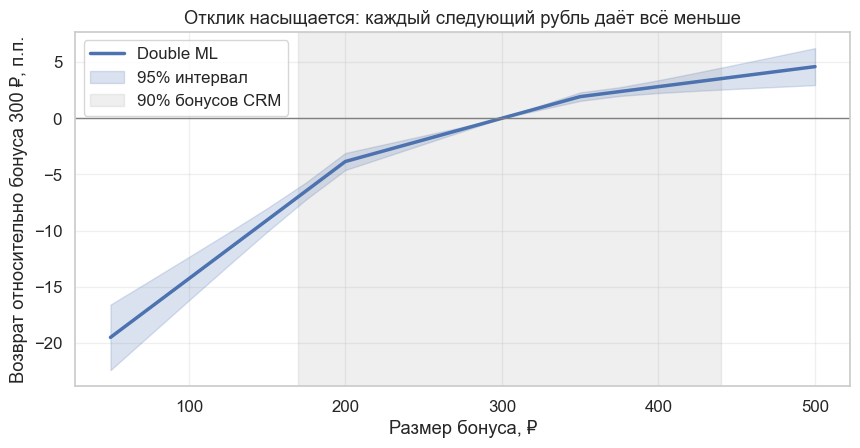

,effect,se,bonus
2,-0.143,0.010,100
6,-0.038,0.004,200
10,0.000,0.000,300
14,0.028,0.003,400
18,0.046,0.008,500


In [39]:
basis = bonus_basis(bonus_h)
basis_res = np.column_stack([basis[:, j] - crossfit_predict(reg_model, sent_rows[FEATURES], basis[:, j], sent_folds)
                             for j in range(basis.shape[1])])
y_res_sent = y_sent - my_sent
GRID = np.arange(50, 501, 25)
REFERENCE = 300
curve = dose_response(y_res_sent, basis_res, bonus_basis(GRID / 100) - bonus_basis(REFERENCE / 100)).assign(bonus=GRID)

# Проверка
slopes = np.diff(curve["effect"].to_numpy()) / 25 * 100
assert slopes[GRID[:-1] < 200].mean() > slopes[(GRID[:-1] >= 350)].mean(), "Кривая должна выгибаться"
assert abs(curve.loc[curve["bonus"] == REFERENCE, "effect"].iloc[0]) < 1e-9

low5, high95 = np.percentile(sent_rows["bonus"], [5, 95])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(curve["bonus"], curve["effect"] * 100, color=BLUE, lw=2.5, label="Double ML")
ax.fill_between(curve["bonus"], (curve["effect"] - Z * curve["se"]) * 100, (curve["effect"] + Z * curve["se"]) * 100,
                color=BLUE, alpha=0.2, label="95% интервал")
ax.axvspan(low5, high95, color=GRAY, alpha=0.12, label="90% бонусов CRM")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("Размер бонуса, ₽")
ax.set_ylabel(f"Возврат относительно бонуса {REFERENCE} ₽, п.п.")
ax.set_title("Отклик насыщается: каждый следующий рубль даёт всё меньше")
ax.legend()
plt.show()
curve[curve["bonus"].isin([100, 200, 300, 400, 500])].round(4)

Отклик насыщается. От 200 до 300 ₽ оценка прибавляет 3.9 п.п., от 300 до 400 ₽ — 2.8 п.п., от 400 до 500 ₽ — 1.8 п.п. Значит, средний наклон 4 п.п. на 100 ₽ нельзя применять ни к какому конкретному участку.

Вне серой полосы кривая почти ни на чём не держится. Интервал там шире, но это только статистическая ошибка: он не учитывает, что на этом участке вся форма кривой задана нашим базисом. CRM почти не давала бонусы меньше 170 ₽, и всё, что левее, — экстраполяция. Проверим это в разделе 10.

Ту же проблему мы видели в лекции 2.11 с ценами: Double ML оценивает участок кривой, на котором жили данные.

## 7. Сверка с библиотекой `DoubleML`

В работе обычно берут готовую реализацию: меньше шансов ошибиться в ошибках и есть анализ чувствительности. Заодно сверим с ней то, что написали руками.

### Задание 12. Те же модели в `DoubleML`

Постройте `DoubleMLData`, укажите `cluster_cols="user_id"`, обучите `DoubleMLPLR` и `DoubleMLIRM` для отправки и `DoubleMLPLR` для размера бонуса. Для PLR с бинарным $T$ модель `ml_m` — классификатор. Для IRM используйте `ps_processor_config=dml.utils.PSProcessorConfig(clipping_threshold=0.01)`. Положите модели в `lib_plr`, `lib_irm`, `lib_bonus`.

In [40]:
columns = FEATURES + ["user_id", "sent", "returned"]
data_sent = dml.DoubleMLData(main[columns], y_col="returned", d_cols="sent", x_cols=FEATURES, cluster_cols="user_id")
data_bonus = dml.DoubleMLData(sent_rows[FEATURES + ["user_id", "returned"]].assign(bonus_h=bonus_h), y_col="returned",
                              d_cols="bonus_h", x_cols=FEATURES, cluster_cols="user_id")

# ВАШ КОД
lib_plr, lib_irm, lib_bonus = None, None, None

In [41]:
# @title Решение (нажмите, чтобы раскрыть)
np.random.seed(0)
lib_plr = dml.DoubleMLPLR(data_sent, ml_l=clone(reg_model), ml_m=clone(clf_model), n_folds=N_FOLDS).fit()
lib_irm = dml.DoubleMLIRM(data_sent, ml_g=clone(reg_model), ml_m=clone(clf_model), n_folds=N_FOLDS,
                          ps_processor_config=dml.utils.PSProcessorConfig(clipping_threshold=0.01)).fit()
lib_bonus = dml.DoubleMLPLR(data_bonus, ml_l=clone(reg_model), ml_m=clone(reg_model), n_folds=N_FOLDS).fit()

In [42]:
compare = pd.DataFrame({
    "Вручную": [plr_main["theta"], estimates.loc["ATE (IRM)", "theta"], bonus_est["theta"]],
    "Ошибка вручную": [plr_main["se"], estimates.loc["ATE (IRM)", "se"], bonus_est["se"]],
    "DoubleML": [lib_plr.coef[0], lib_irm.coef[0], lib_bonus.coef[0]],
    "Ошибка DoubleML": [lib_plr.se[0], lib_irm.se[0], lib_bonus.se[0]],
}, index=["Отправка, PLR", "Отправка, IRM", "Бонус на 100 ₽, PLR"])

# Проверка
assert (abs(compare["Вручную"] - compare["DoubleML"]) < 3 * compare["Ошибка вручную"]).all(), "Расхождение больше шума"
compare.round(4)

,Вручную,Ошибка вручную,DoubleML,Ошибка DoubleML
"Отправка, PLR",0.241,0.003,0.241,0.003
"Отправка, IRM",0.212,0.004,0.212,0.004
"Бонус на 100 ₽, PLR",0.040,0.002,0.040,0.002


Ручные оценки и библиотека совпали с точностью до шума разбиения, значит, в формулах нет ошибок. Фолды по пользователям при `cluster_cols` библиотека строит сама.

Библиотека умеет ещё `gate()` и `cate()` для заранее заданных групп и базиса, а `policy_tree()` только для IRM с бинарным воздействием. Для нескольких размеров бонуса в разделе 9 логику пишем сами.

## 8. Чувствительность к скрытым конфаундерам

Все предыдущие проверки касались только того, что есть в данных. Самая опасная гипотеза, что мы учли всё, ими не проверяется. Но мы можем спросить иначе: **насколько сильным должен быть скрытый конфаундер, чтобы вывод изменился?**

Подход Черножукова, Синелли и соавторов описывает скрытую переменную двумя числами:

* $c_Y$ (`cf_y`): какую долю остаточной дисперсии $Y$ она объясняет;
* $c_T$ (`cf_d`): какую долю остаточной дисперсии $T$ она объясняет.

Смещение ограничено выражением вида $|\text{смещение}| \le |\rho| \cdot S \cdot \sqrt{c_Y \cdot \frac{c_T}{1 - c_T}}$, где $S$ оценивается по данным, а $\rho$ — корреляция между тем, как скрытая переменная влияет на $Y$ и на $T$. Библиотека по умолчанию берёт худший случай $\rho = 1$.

**Robustness value (RV)** — значение $c_Y = c_T$, при котором нижняя граница доходит до нуля. Анализ делаем для PLR: параметры здесь читаются как обычные $R^2$, тогда как в IRM $c_T$ определён сложнее.

Использовать будем модель без кластеров: документация не описывает, как оценка границ работает вместе с ними.

### Задание 13. Карта чувствительности

Реализуйте `lower_bound_grid(model, cf_values)`: для каждой пары $(c_Y, c_T)$ вызовите `model.sensitivity_analysis(cf_y=..., cf_d=...)` и прочитайте нижнюю границу из `model.sensitivity_params["theta"]["lower"][0]`. Верните матрицу, где строки соответствуют $c_T$, а столбцы $c_Y$.

In [43]:
data_plain = dml.DoubleMLData(main[FEATURES + ["sent", "returned"]], y_col="returned", d_cols="sent", x_cols=FEATURES)
np.random.seed(0)
sens_model = dml.DoubleMLPLR(data_plain, ml_l=clone(reg_model), ml_m=clone(clf_model), n_folds=N_FOLDS).fit()


def lower_bound_grid(model, cf_values) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [44]:
# @title Решение (нажмите, чтобы раскрыть)
def lower_bound_grid(model, cf_values) -> np.ndarray:
    grid = np.zeros((len(cf_values), len(cf_values)))
    for i, cf_d in enumerate(cf_values):
        for j, cf_y in enumerate(cf_values):
            model.sensitivity_analysis(cf_y=cf_y, cf_d=cf_d)
            grid[i, j] = model.sensitivity_params["theta"]["lower"][0]
    return grid

RV = 18.7%, при c_Y = c_T = 0.03 граница +0.206...+0.277


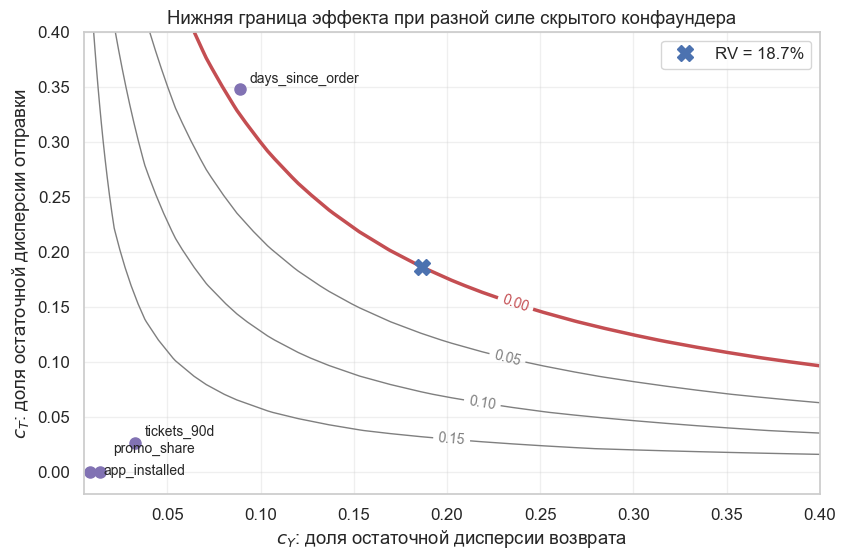

,cf_y,cf_d,rho,delta_theta
feature,,,,
days_since_order,0.089,0.348,-0.960,-0.170
tickets_90d,0.033,0.027,-0.712,-0.024
promo_share,0.014,0.000,-1.000,-0.001
app_installed,0.009,0.000,-0.231,-0.000


In [45]:
CF = np.linspace(0.005, 0.40, 25)
bound_grid = lower_bound_grid(sens_model, CF)

# Проверка
assert bound_grid[0, 0] > bound_grid[-1, -1], "Чем сильнее конфаундер, тем ниже граница"
assert bound_grid[0, 0] < sens_model.coef[0]

sens_model.sensitivity_analysis(cf_y=0.03, cf_d=0.03)
robustness = sens_model.sensitivity_params["rv"][0]
benchmarks = pd.concat([sens_model.sensitivity_benchmark(benchmarking_set=[name]).assign(feature=name)
                        for name in ["days_since_order", "tickets_90d", "promo_share", "app_installed"]]).set_index("feature")

print(f"RV = {robustness:.1%}, при c_Y = c_T = 0.03 граница {sens_model.sensitivity_params['theta']['lower'][0]:+.3f}"
      f"...{sens_model.sensitivity_params['theta']['upper'][0]:+.3f}")
LABEL_SHIFT = {"days_since_order": (7, 5), "tickets_90d": (7, 5), "promo_share": (10, 14), "app_installed": (10, -2)}

fig, ax = plt.subplots(figsize=(9.5, 6))
levels = [0, 0.05, 0.10, 0.15]
contour = ax.contour(CF, CF, bound_grid, levels=levels, colors=[RED] + [GRAY] * 3, linewidths=[2.5, 1, 1, 1])
ax.clabel(contour, fmt="%.2f", fontsize=10)
ax.plot(robustness, robustness, marker="X", ms=12, color=BLUE, ls="", label=f"RV = {robustness:.1%}")
for name, row in benchmarks.iterrows():
    point = (min(row["cf_y"], 0.4), min(row["cf_d"], 0.4))
    ax.plot(*point, marker="o", ms=8, color=PURPLE, ls="")
    ax.annotate(name, point, xytext=LABEL_SHIFT[name], textcoords="offset points", fontsize=10)
ax.set_xlabel("$c_Y$: доля остаточной дисперсии возврата")
ax.set_ylabel("$c_T$: доля остаточной дисперсии отправки")
ax.set_title("Нижняя граница эффекта при разной силе скрытого конфаундера")
ax.legend(loc="upper right")
plt.show()
benchmarks.round(4)

Как читать график:

* **Красная линия** — где нижняя граница доходит до нуля. RV = 18.7%: чтобы отменить положительный эффект, скрытая переменная должна объяснять больше 18.7% остаточной дисперсии и возврата, и отправки сразу.
* **Фиолетовые точки** — наблюдаемые признаки. Показывают, насколько упала бы оценка, если бы мы их забыли, и служат эталоном для правдоподобия. `days_since_order` лежит чуть за красной линией: это самый сильный признак, он объясняет 35% остаточной дисперсии отправки. `tickets_90d` гораздо слабее, а `promo_share` и `app_installed` почти не связаны с отправкой.

**Вывод.** Положительный эффект устойчив: скрытая переменная должна быть сильнее всего, что у нас есть, кроме давности. Но о **размере** эффекта так сказать нельзя. Переменная силы `tickets_90d` ($c_Y \approx c_T \approx 0.03$) допускает диапазон от +20.6 до +27.7 п.п. Поэтому в отчёт идёт не «эффект 24 п.п.», а «эффект положителен, и его размер известен с точностью до скрытых факторов».

Нужно понимать, что это за граница. Она показывает, что будет **при заданной силе** конфаундера, но не говорит, какая сила верна: это решается знанием предметной области. В статье о кейсе Booking.com (данные там симулированы по мотивам реальной задачи) силу задавали через прокси-признаки лояльности, а правдоподобие сценариев обсуждали с экспертами. При самом сильном сценарии эффект перестал быть устойчивым, но эксперты сочли этот сценарий неправдоподобным.

Здесь $\rho = 1$, то есть худший случай. У реальных признаков $|\rho|$ бывает гораздо меньше, например, 0.23 у `app_installed`, поэтому граница консервативна. Наша RV относится к точечной границе, а RVa из `sensitivity_params` учитывает ещё и статистическую ошибку.

## 9. Кому и сколько

Средний эффект не отвечает на вопрос бизнеса. Бонус — это деньги: он списывается у всех, кто вернулся, в том числе у тех, кто вернулся бы и так. Поэтому дальше смотрим на **прибыль** с пользователя: маржа минус списанный бонус. Начнём с того, у кого эффект на возврат выше всего.

### Задание 14. Эффект по сегментам

У AIPW есть удобное свойство: $\psi_i$ можно усреднять по любой подгруппе. Реализуйте `gate(psi, segment, groups)`: для каждого значения `segment` верните `effect`, `se` (через `score_summary`) и число строк `n`.

In [46]:
def gate(psi, segment, groups) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [47]:
# @title Решение (нажмите, чтобы раскрыть)
def gate(psi, segment, groups) -> pd.DataFrame:
    segment, groups = pd.Series(np.asarray(segment)), np.asarray(groups)
    rows = {}
    for value in segment.dropna().unique():
        mask = (segment == value).to_numpy()
        est = score_summary(psi[mask], groups[mask])
        rows[value] = {"effect": est["theta"], "se": est["se"], "n": mask.sum()}
    return pd.DataFrame(rows).T.sort_index()

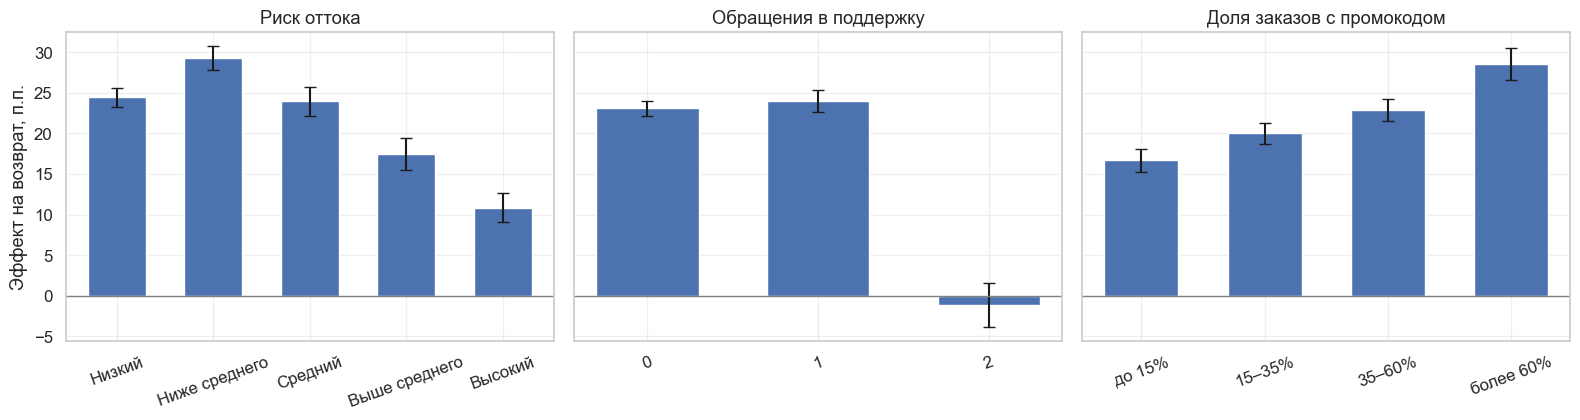

Доля отправок по числу обращений: {0: 0.641, 1: 0.735, 2: 0.815}


effect    se          n
Риск оттока               Низкий          0.245 0.006 26,398.000
                          Ниже среднего   0.293 0.007 26,398.000
                          Средний         0.239 0.009 26,397.000
                          Выше среднего   0.175 0.010 26,398.000
                          Высокий         0.109 0.009 26,398.000
Обращения в поддержку     0               0.231 0.005 77,444.000
                          1               0.240 0.007 42,759.000
                          2              -0.012 0.014 11,786.000
Доля заказов с промокодом до 15%          0.167 0.007 31,110.000
                          15–35%          0.200 0.007 44,476.000
                          35–60%          0.229 0.007 38,672.000
                          более 60%       0.286 0.010 17,731.000

In [48]:
churn_score = 1 - mu0     # прогноз «не вернётся без бонуса»: так сегодня выбирают, кому писать
churn_group = pd.qcut(churn_score, 5, labels=["Низкий", "Ниже среднего", "Средний", "Выше среднего", "Высокий"])
promo_group = pd.cut(main["promo_share"], [-0.01, 0.15, 0.35, 0.6, 1], labels=["до 15%", "15–35%", "35–60%", "более 60%"])

gates = {
    "Риск оттока": gate(psi_ate, churn_group.astype(str), groups).reindex(["Низкий", "Ниже среднего", "Средний", "Выше среднего", "Высокий"]),
    "Обращения в поддержку": gate(psi_ate, main["tickets_90d"], groups),
    "Доля заказов с промокодом": gate(psi_ate, promo_group.astype(str), groups).reindex(["до 15%", "15–35%", "35–60%", "более 60%"]),
}

# Проверка
assert gates["Обращения в поддержку"].loc[2, "effect"] < 0.03, "У обиженных пользователей эффект должен быть около нуля или ниже"
assert gates["Риск оттока"].loc["Высокий", "effect"] < gates["Риск оттока"].loc["Средний", "effect"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, (name, table) in zip(axes, gates.items()):
    pos = np.arange(len(table))
    ax.bar(pos, table["effect"] * 100, yerr=Z * table["se"] * 100, color=BLUE, width=0.6, capsize=4)
    ax.axhline(0, color=GRAY, lw=1)
    ax.set_xticks(pos, [str(v) for v in table.index], rotation=20)
    ax.set_title(name)
axes[0].set_ylabel("Эффект на возврат, п.п.")
plt.tight_layout()
plt.show()
share_by_ticket = main.groupby("tickets_90d")["sent"].mean()
print("Доля отправок по числу обращений:", share_by_ticket.round(3).to_dict())
pd.concat(gates).round(4)

Самый важный график практики:

* **Риск оттока.** Эффект падает с 29 п.п. в группе с невысоким риском до 11 п.п. в группе с самым высоким. Самые потерянные пользователи реагируют слабее всего. Это главный вывод работы Аскарзы Retention Futility: те, кто больше всех рискует уйти, не обязательно лучшая цель. А CRM выбирает именно их.
* **Обращения в поддержку.** При двух обращениях эффект около нуля, а бонус получает 81.5% таких людей: это самая высокая доля. CRM считала их срочными, но деньги тратятся впустую. Возможно, письмо ещё и напоминает о плохом опыте.
* **Промокоды.** Эффект растёт с 17 до 29 п.п. вместе с долей заказов с промокодом. Те, кто любит скидки, на бонус и реагируют.

### Задание 15. Прибыль по размерам бонуса

Разобьём воздействие на четыре уровня: **без бонуса**, **до 150 ₽**, **200–300 ₽** и **от 350 ₽**. Это обобщение AIPW на несколько вариантов:

$$
\Gamma_{ik} = \hat{\mu}_k(X_i) + \frac{\mathbb{1}[A_i = k]\,(Y_i - \hat{\mu}_k(X_i))}{\hat{e}_k(X_i)}
$$

Среднее $\Gamma_{ik}$ оценивает среднюю прибыль, если всем дать уровень $k$. Разность $\Gamma_{ik} - \Gamma_{i0}$ можно использовать как цель обычной регрессии на $X$: это **DR-learner**, и он даёт оценку CATE.

Реализуйте `arm_scores(df, y, arm, folds, n_arms, clip)`: получите кросс-предсказания $\hat{\mu}_k$ (модель `reg_model` на строках своего уровня) и $\hat{e}_k$ (классификатор на все уровни), обрежьте $\hat{e}_k$ снизу значением `clip` и верните матрицу $\Gamma$.

In [49]:
ARMS = ["Без бонуса", "До 150 ₽", "200–300 ₽", "От 350 ₽"]
BONUS_MEAN = np.array([0, 100, 250, 425])


def add_profit(df: pd.DataFrame) -> pd.DataFrame:
    arm = np.select([df["sent"] == 0, df["bonus"] <= 150, df["bonus"] <= 300], [0, 1, 2], 3)
    return df.assign(profit=df["margin"] - df["bonus"] * df["returned"], arm=arm)


main = add_profit(main)
arm_clf = LGBMClassifier(**LGBM)


def arm_scores(df: pd.DataFrame, y, arm, folds, n_arms: int = 4, clip: float = 0.01) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [50]:
# @title Решение (нажмите, чтобы раскрыть)
def arm_scores(df: pd.DataFrame, y, arm, folds, n_arms: int = 4, clip: float = 0.01) -> np.ndarray:
    y, arm, X_all = np.asarray(y, float), np.asarray(arm), df[FEATURES]
    mu, prop = np.zeros((len(y), n_arms)), np.zeros((len(y), n_arms))
    for train_idx, valid_idx in folds:
        prop[valid_idx] = clone(arm_clf).fit(X_all.iloc[train_idx], arm[train_idx]).predict_proba(X_all.iloc[valid_idx])
        for k in range(n_arms):
            part = train_idx[arm[train_idx] == k]
            mu[valid_idx, k] = clone(reg_model).fit(X_all.iloc[part], y[part]).predict(X_all.iloc[valid_idx])
    prop = np.clip(prop, clip, 1)
    return mu + np.eye(n_arms)[arm] * (y[:, None] - mu) / prop

In [51]:
gamma = arm_scores(main, main["profit"], main["arm"], folds)

# Проверка
assert gamma.shape == (len(main), 4)
arm_table = pd.DataFrame({"Доля у CRM": main["arm"].value_counts(normalize=True).sort_index().to_numpy(),
                          "Сырая прибыль": main.groupby("arm")["profit"].mean().to_numpy(),
                          "Оценка AIPW": gamma.mean(axis=0)}, index=ARMS)
assert arm_table["Оценка AIPW"].iloc[3] < arm_table["Оценка AIPW"].iloc[0], "Большой бонус всем не окупается"
arm_table.round(3)

,Доля у CRM,Сырая прибыль,Оценка AIPW
Без бонуса,0.313,238.242,185.602
До 150 ₽,0.025,262.842,204.546
200–300 ₽,0.324,183.999,183.290
От 350 ₽,0.337,101.552,144.280


Что видно в таблице:

* **Сырая прибыль и AIPW сильно расходятся.** В сырых цифрах уровень 200–300 ₽ хуже отсутствия бонуса на 54 ₽, а с поправкой на отбор всего на 2 ₽.
* **Большой бонус не окупается.** Оценка «всем от 350 ₽» на 41 ₽ хуже, чем «никому»: бонус списывают и те, кто вернулся бы сам.
* **Средний бонус всем** почти в нуле. Эффект на возврат большой, +21 п.п., но прибыль не растёт. Вот почему нельзя останавливаться на эффекте по основной метрике.
* **Низкий бонус выглядит лучшим**, но у CRM такой уровень встречался только в 2.5% строк, поэтому этой оценке доверять меньше всего.

Обучим финальные модели: по одной на каждый размер бонуса, цель — разность $\Gamma_{ik} - \Gamma_{i0}$. Деревья берём маленькие: цель очень шумная. Получим оценку прироста прибыли для каждого пользователя и три правила.

* **По риску:** бонус 200–300 ₽ получают 40% пользователей с самым высоким риском оттока. Так выглядит обычная практика.
* **По эффекту:** бонус 200–300 ₽ получают 40% пользователей с самой высокой оценкой прироста. Писем столько же, отбор другой.
* **Персональный:** каждому свой уровень с наибольшей оценкой прироста, в том числе «без бонуса».

Все модели учатся только на данных CRM. Случайную группу мы пока не открывали.

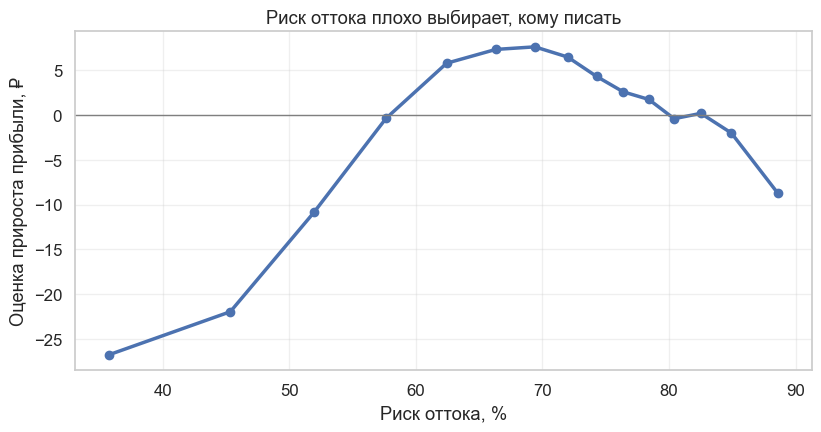

Персональное правило: {'Без бонуса': 0.335, 'До 150 ₽': 0.374, '200–300 ₽': 0.231, 'От 350 ₽': 0.06}


In [52]:
cate_params = {**LGBM, "n_estimators": 120, "num_leaves": 7, "min_child_samples": 200}
cate_models = [LGBMRegressor(**cate_params).fit(main[FEATURES], gamma[:, k] - gamma[:, 0]) for k in (1, 2, 3)]
churn_model = LGBMClassifier(**LGBM).fit(main.loc[main["sent"] == 0, FEATURES], main.loc[main["sent"] == 0, "returned"])
TARGET_SHARE = 0.4


def predict_gain(df: pd.DataFrame) -> np.ndarray:
    """Оценка прироста прибыли от каждого уровня бонуса относительно отсутствия бонуса."""
    return np.column_stack([np.zeros(len(df))] + [model.predict(df[FEATURES]) for model in cate_models])


def make_policies(df: pd.DataFrame) -> dict:
    gain = predict_gain(df)
    risk = churn_model.predict_proba(df[FEATURES])[:, 0]
    top = lambda score: score >= np.quantile(score, 1 - TARGET_SHARE)
    return {"Никому": np.zeros(len(df), dtype=int), "Всем 200–300 ₽": np.full(len(df), 2),
            "По риску, 40%": top(risk) * 2, "По эффекту, 40%": top(gain[:, 2]) * 2, "Персональный": gain.argmax(axis=1)}


own_gain, own_risk = predict_gain(main), churn_model.predict_proba(main[FEATURES])[:, 0]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
table = pd.DataFrame({"risk": own_risk, "gain": own_gain[:, 2]}).groupby(pd.qcut(own_risk, 15), observed=True).mean()
ax.plot(table["risk"] * 100, table["gain"], marker="o", color=BLUE, lw=2.5)
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("Риск оттока, %")
ax.set_ylabel("Оценка прироста прибыли, ₽")
ax.set_title("Риск оттока плохо выбирает, кому писать")
plt.show()
print("Персональное правило:", {k: round(float(v), 3) for k, v in zip(ARMS, np.bincount(own_gain.argmax(axis=1), minlength=4) / len(main))})

## 10. Открываем случайную группу

Четверть базы CRM не трогала: там отправка и размер бонуса случайны. Здесь мы впервые можем проверить свои выводы.

In [53]:
holdout_all = add_profit(load("reactivation_holdout.csv"))
holdout = holdout_all[holdout_all["tickets_90d"] <= MAX_TICKETS].reset_index(drop=True)
balance = holdout.groupby("sent")[["days_since_order", "orders_total", "avg_check", "promo_share", "tickets_90d"]].mean()
print(holdout.shape, f"отправка: {holdout['sent'].mean():.3f}, SRM p = {stats.binomtest(int(holdout['sent'].sum()), len(holdout)).pvalue:.3f}")
balance

(43589, 16) отправка: 0.504, SRM p = 0.130


,days_since_order,orders_total,avg_check,promo_share,tickets_90d
sent,,,,,
0,103.472,6.915,"1,606.739",0.334,0.507
1,103.589,6.943,"1,613.257",0.332,0.499


### Задание 16. Сверка эффекта

Простое сравнение со случайной группой будет ошибкой: там бонусы равномерны от 50 до 500 ₽, а у CRM сосредоточены около 300 ₽. Значит, это разные воздействия. Чтобы сравнить одно и то же, ограничим случайную группу диапазоном бонусов CRM.

Реализуйте `holdout_effect(df, low, high)`: разность долей вернувшихся между строками с бонусом в диапазоне $[low, high]$ и строками без бонуса. Воздействие здесь назначено случайно для каждой строки, поэтому хватит обычной ошибки разности долей и нормального интервала. Верните словарь `theta`, `se`, `low`, `high`.

In [54]:
def holdout_effect(df: pd.DataFrame, low: int, high: int) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [55]:
# @title Решение (нажмите, чтобы раскрыть)
def holdout_effect(df: pd.DataFrame, low: int, high: int) -> dict:
    treated = df.loc[(df["sent"] == 1) & df["bonus"].between(low, high), "returned"]
    control = df.loc[df["sent"] == 0, "returned"]
    theta = treated.mean() - control.mean()
    se = np.sqrt(treated.var() / len(treated) + control.var() / len(control))
    return {"theta": theta, "se": se, "low": theta - Z * se, "high": theta + Z * se}

ATE минус случайная группа: +0.0223 ± 0.0125, z = 3.50


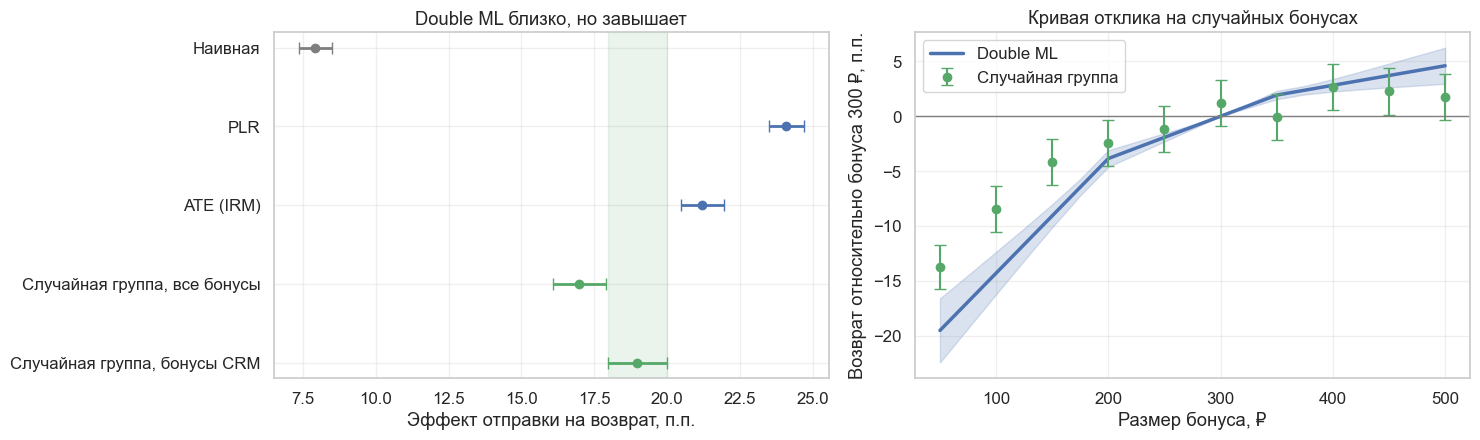

Наклон на 100 ₽ в диапазоне 150–450 ₽: случайная группа +0.0219, Double ML +0.0400
Double ML, п.п.: {50: -19.5, 100: -14.3, 200: -3.9, 400: 2.8, 500: 4.6}
Случайная группа, п.п.: {50: -13.7, 100: -8.4, 200: -2.4, 400: 2.6, 500: 1.8}


,theta,se,low,high
Наивная,0.079,0.003,NaN,NaN
PLR,0.241,0.003,0.235,0.247
ATE (IRM),0.212,0.004,0.205,0.220
"Случайная группа, все бонусы",0.170,0.005,0.161,0.179
"Случайная группа, бонусы CRM",0.190,0.005,0.180,0.200


In [56]:
# Проверка
hold_all = holdout_effect(holdout, 50, 500)
hold_crm = holdout_effect(holdout, 150, 450)
assert hold_crm["theta"] > hold_all["theta"], "В диапазоне CRM бонусы выше, эффект должен быть больше"

verdict = pd.DataFrame({
    "Наивная": {"theta": naive["gap"], "se": np.sqrt(naive["returned_1"] * (1 - naive["returned_1"]) / crm["sent"].sum()
                                                     + naive["returned_0"] * (1 - naive["returned_0"]) / (1 - crm["sent"]).sum())},
    "PLR": plr_main, "ATE (IRM)": estimates.loc["ATE (IRM)"].to_dict(),
    "Случайная группа, все бонусы": hold_all, "Случайная группа, бонусы CRM": hold_crm}).T.astype(float)
diff = verdict.loc["ATE (IRM)", "theta"] - hold_crm["theta"]
diff_se = np.hypot(verdict.loc["ATE (IRM)", "se"], hold_crm["se"])
print(f"ATE минус случайная группа: {diff:+.4f} ± {Z * diff_se:.4f}, z = {diff / diff_se:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
order = verdict.iloc[::-1]
colors = [GREEN, GREEN, BLUE, BLUE, GRAY]
for (name, row), color in zip(order.iterrows(), colors):
    axes[0].errorbar(row["theta"] * 100, name, xerr=Z * row["se"] * 100, fmt="o", color=color, capsize=4, lw=2)
axes[0].axvspan((hold_crm["low"]) * 100, (hold_crm["high"]) * 100, color=GREEN, alpha=0.12)
axes[0].set_xlabel("Эффект отправки на возврат, п.п.")
axes[0].set_title("Double ML близко, но завышает")

hold_bonus = holdout[holdout["sent"] == 1].groupby("bonus")["returned"].agg(["mean", "size"])
reference = hold_bonus.loc[250:350, "mean"].mean()
hold_se = np.sqrt(hold_bonus["mean"] * (1 - hold_bonus["mean"]) / hold_bonus["size"])
axes[1].plot(curve["bonus"], curve["effect"] * 100, color=BLUE, lw=2.5, label="Double ML")
axes[1].fill_between(curve["bonus"], (curve["effect"] - Z * curve["se"]) * 100, (curve["effect"] + Z * curve["se"]) * 100, color=BLUE, alpha=0.2)
axes[1].errorbar(hold_bonus.index, (hold_bonus["mean"] - reference) * 100, yerr=Z * hold_se * 100, fmt="o", color=GREEN, capsize=4, label="Случайная группа")
axes[1].axhline(0, color=GRAY, lw=1)
axes[1].set_xlabel("Размер бонуса, ₽")
axes[1].set_ylabel("Возврат относительно бонуса 300 ₽, п.п.")
axes[1].set_title("Кривая отклика на случайных бонусах")
axes[1].legend()
plt.tight_layout()
plt.show()
in_range = holdout[(holdout["sent"] == 1) & holdout["bonus"].between(150, 450)]
print(f"Наклон на 100 ₽ в диапазоне 150–450 ₽: случайная группа {np.polyfit(in_range['bonus'] / 100, in_range['returned'], 1)[0]:+.4f}, Double ML {bonus_est['theta']:+.4f}")
at_points = curve.set_index("bonus")["effect"].reindex([50, 100, 200, 400, 500]) * 100
print("Double ML, п.п.:", at_points.round(1).to_dict())
print("Случайная группа, п.п.:", ((hold_bonus["mean"] - reference) * 100).reindex([50, 100, 200, 400, 500]).round(1).to_dict())
verdict.round(4)

Сравниваем с истинным экспериментом:

* **Сравнивать нужно одно и то же.** Со всеми бонусами случайная группа даёт +17.0 п.п., с бонусами из диапазона CRM +19.0 п.п. Разница появилась только из-за другого набора бонусов, а не из-за ошибки метода.
* **ATE завышен на 2.2 п.п.**, и разница значима: $z = 3.5$. Интервал +20.5...+22.0 п.п. не содержит правду. Это след скрытой активности: её влияние мы не могли убрать, зато могли заранее оценить его размер в разделе 8.
* **Наивная оценка** ошиблась намного сильнее, на 11 п.п. Double ML убрал бóльшую часть смещения, но не всё.
* **Кривая отклика.** В диапазоне CRM форма кривой близка к случайным данным: при 400 ₽ получается +2.8 против +2.6 п.п. относительно 300 ₽. Левее 200 ₽ оценка завышает провал: при бонусе 50 ₽ получается −19.5 п.п. против −13.7 п.п. на случайных данных. Такова цена экстраполяции, и интервал её не показывал.
* **Средний наклон.** В диапазоне 150–450 ₽ случайная группа даёт +2.2 п.п. на 100 ₽, а Double ML +4.0 п.п. Часть разницы даёт скрытая активность, часть другие веса бонусов. Кривая здесь полезнее одного числа.

**Насколько это надёжно.** Мы прогнали генератор с пятью зёрнами. Оценка ATE стабильна (от +20.9 до +21.3 п.п.), а случайная группа шумит (от +18.4 до +20.4 п.п.), и $z$ меняется от 1.4 до 3.9. При другом зерне мы могли бы и не заметить смещение: маленькая случайная группа защищает только от больших ошибок.

### Задание 17. Ценность правил

Для каждого правила нас интересует, сколько прибыли оно принесло бы на случайной группе. Там известны вероятности уровней: `ARM_PROB`. Нельзя просто взять среднее по совпадениям с правилом, потому что уровни встречаются с разной частотой, поэтому строкам даём вес $1 / P(A_i)$:

$$
\hat{V}(\pi) = \frac{\sum_i w_i Y_i}{\sum_i w_i}, \qquad w_i = \frac{\mathbb{1}[A_i = \pi(X_i)]}{P(A_i)}
$$

Реализуйте `policy_value(profit, arm, policy, weights=None)`, где `weights` — веса строк из бутстрепа. Функция `policy_bootstrap` ниже использует её и ресэмплирует пользователей.

In [57]:
ARM_PROB = np.array([0.5, 0.15, 0.15, 0.2])   # 50% без бонуса, остальное делят 10 равновероятных бонусов


def policy_value(profit, arm, policy, weights=None) -> float:
    # ВАШ КОД
    raise NotImplementedError


def policy_bootstrap(df: pd.DataFrame, policies: dict, reference: str = "Никому", n_boot: int = 500, seed: int = 0) -> pd.DataFrame:
    """Сравнивает правила с эталонным и строит интервалы бутстрепом по пользователям."""
    rng = np.random.default_rng(seed)
    codes, n_users = pd.factorize(df["user_id"])[0], df["user_id"].nunique()
    profit, arm = df["profit"].to_numpy(float), df["arm"].to_numpy()
    rows = {}
    draws = [rng.multinomial(n_users, np.full(n_users, 1 / n_users))[codes] for _ in range(n_boot)]
    for name, policy in policies.items():
        gain = [policy_value(profit, arm, policy, w) - policy_value(profit, arm, policies[reference], w) for w in draws]
        rows[name] = {"gain": policy_value(profit, arm, policy) - policy_value(profit, arm, policies[reference]),
                      "low": np.percentile(gain, 2.5), "high": np.percentile(gain, 97.5), "sent_share": np.mean(policy > 0)}
    return pd.DataFrame(rows).T

In [58]:
# @title Решение (нажмите, чтобы раскрыть)
def policy_value(profit, arm, policy, weights=None) -> float:
    w = (arm == policy) / ARM_PROB[arm]
    if weights is not None:
        w = w * weights
    return float((w * profit).sum() / w.sum())

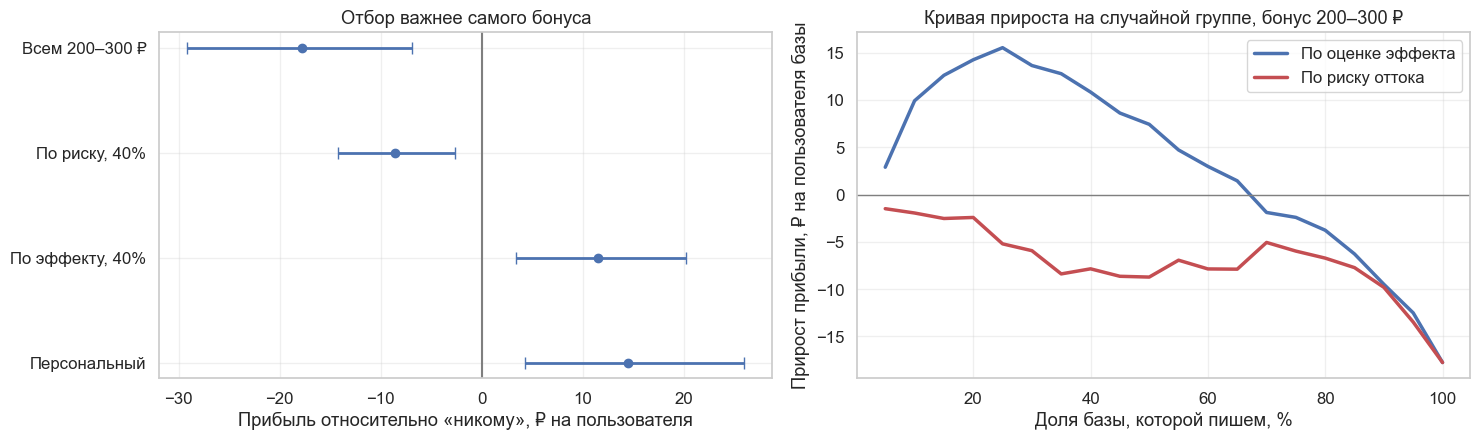

,gain,low,high,sent_share
Никому,0.000,0.000,0.000,0.000
Всем 200–300 ₽,-17.750,-29.150,-6.890,1.000
"По риску, 40%",-8.620,-14.200,-2.580,0.400
"По эффекту, 40%",11.540,3.380,20.210,0.400
Персональный,14.450,4.260,26.030,0.670


In [59]:
# Проверка: правило «всегда уровень 2» равно средней прибыли этого уровня
assert abs(policy_value(holdout["profit"].to_numpy(float), holdout["arm"].to_numpy(), np.full(len(holdout), 2))
           - holdout.loc[holdout["arm"] == 2, "profit"].mean()) < 1e-6

policies = make_policies(holdout)
values = policy_bootstrap(holdout, policies)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
order = values.drop(index="Никому").iloc[::-1]
axes[0].errorbar(order["gain"], order.index, xerr=[order["gain"] - order["low"], order["high"] - order["gain"]],
                 fmt="o", color=BLUE, capsize=4, lw=2)
axes[0].axvline(0, color=GRAY, lw=1.5)
axes[0].set_xlabel("Прибыль относительно «никому», ₽ на пользователя")
axes[0].set_title("Отбор важнее самого бонуса")


def gain_curve(df: pd.DataFrame, score: np.ndarray, arm: int = 2, points: int = 20) -> tuple:
    """Прирост прибыли на пользователя базы, если писать только верхним k% по score."""
    order = np.argsort(-score)
    profit, arms = df["profit"].to_numpy(float)[order], df["arm"].to_numpy()[order]
    shares = np.linspace(0.05, 1, points)
    gains = []
    for share in shares:
        top = int(share * len(df))
        gains.append((profit[:top][arms[:top] == arm].mean() - profit[:top][arms[:top] == 0].mean()) * share)
    return shares * 100, np.array(gains)


holdout_gain, holdout_risk = predict_gain(holdout), churn_model.predict_proba(holdout[FEATURES])[:, 0]
for score, color, label in [(holdout_gain[:, 2], BLUE, "По оценке эффекта"), (holdout_risk, RED, "По риску оттока")]:
    share, gains = gain_curve(holdout, score)
    axes[1].plot(share, gains, color=color, lw=2.5, label=label)
axes[1].axhline(0, color=GRAY, lw=1)
axes[1].set_xlabel("Доля базы, которой пишем, %")
axes[1].set_ylabel("Прирост прибыли, ₽ на пользователя базы")
axes[1].set_title("Кривая прироста на случайной группе, бонус 200–300 ₽")
axes[1].legend()
plt.tight_layout()
plt.show()
values.round(2)

Что показывает случайная группа:

* **Всем бонус 200–300 ₽:** −18 ₽ на пользователя против «никому». Хотя эффект на возврат большой.
* **По риску оттока, 40%:** −9 ₽. Самое распространённое правило в этой задаче теряет деньги.
* **По эффекту, 40%:** +12 ₽. Писем столько же, отбор другой, и знак сменился.
* **Персональный:** +14 ₽, интервал шире, и он пересекается с предыдущим. Разница между двумя лучшими правилами не доказана.

На правом графике кривая по эффекту выше кривой по риску на всём участке. Максимум у неё около 25% базы, а не 40%. Но выбирать точку максимума на шумной кривой опасно. Обе кривые сходятся справа: если писать всем, отбор неважен.

**Насколько это надёжно.** Разброс по пяти зёрнам большой: «по эффекту» от +2 до +14 ₽, «по риску» от −14 до +4 ₽, «персональный» от +5 до +20 ₽. Но порядок «всем», «по риску», «по эффекту» сохранился во всех пяти прогонах, а истинные значения стабильны, см. ниже.

### Что было на самом деле

Истинные параметры лежат в [`data/generate_data.py`](data/generate_data.py). Значения считаются для пользователей с 0–2 обращениями.

| Что оцениваем | Истина | Double ML | Смещение |
|---|---|---|---|
| ATE при бонусах CRM | +19.5 п.п. | +21.2 п.п. | +1.7 |
| ATT | +17.0 п.п. | +19.7 п.п. | +2.7 |
| Средний эффект с весами $e(1-e)$ | +22.6 п.п. | +24.1 п.п. | +1.5 |

| Правило | Истинный прирост прибыли, ₽ на пользователя (5 зёрен) | Измерено на случайной группе |
|---|---|---|
| Всем 200–300 ₽ | от −22 до −21 | −18 |
| По риску, 40% | от −7 до −6 | −9 |
| По эффекту, 40% | от +9 до +12 | +12 |
| Персональный | от +11 до +19 | +14 |

Скрытая свежая активность в генераторе объясняет 2.8% остаточной дисперсии и возврата, и отправки. Если добавить её в модель, PLR упадёт с +24.1 до +21.1 п.п.: это смещение в 3 п.п. Граница из раздела 8 для $c_Y = c_T = 0.03$ равна +20.6 п.п. и покрывает этот случай. То есть анализ чувствительности дал бы верный диапазон ещё до того, как мы открыли случайную группу, если бы мы правильно угадали силу конфаундера.

## 11. Решение и регламент

### Задание 18. Решение

Напишите руководителю три–четыре предложения: окупается ли программа и что с ней делать. Какой следующий эксперимент вы запустите?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

**Бонус возвращает пользователей, но текущее правило теряет деньги.** Эффект на возврат большой (около +19 п.п. на случайных данных), однако бонус забирают и те, кто вернулся бы сам. Поэтому отправка по риску оттока приносит меньше, чем отсутствие рассылки.

**Что меняем сейчас:**

1. Перестаём выбирать получателей по риску оттока. Отправляем тем, у кого оценка прироста прибыли положительна: около 40% базы.
2. Перестаём слать бонус пользователям с двумя обращениями.
3. Отказываемся от бонусов выше 300 ₽: в среднем они не окупаются.

**Что проверяем тестом.** Лучшим выглядит бонус до 150 ₽, но этот вывод держится на 2.5% данных CRM. Запускаем A/B-тест: 100 ₽ против 250 ₽ на выбранной группе, с прибылью как основной метрикой. Случайную группу сохраняем на постоянной основе: только она показала смещение.

</details>

### Регламент для команды

| Шаг | Что делаем | Что считаем проблемой |
|---|---|---|
| Признаки | Выбираем по графу, до модели. Всё, что случилось после воздействия, исключаем | Автоматический отбор признаков |
| Мешающие модели | Смотрим $R^2$, AUC, калибровку | AUC около 1: остаточной вариации нет |
| Перекрытие | Смотрим распределение $\hat{e}$ и жёсткие правила | Группы без одного из вариантов. Их исключаем и пишем об этом |
| Оценка | Выбираем ATE, ATT или PLR под вопрос, считаем AIPW и PLR вместе | Расхождение из-за обрезки |
| Разбиения | Повторяем кросс-фиттинг, берём медиану | Разброс больше стандартной ошибки |
| Непрерывное воздействие | Смотрим кривую и зону реальных значений | Выводы вне зоны данных |
| Чувствительность | Считаем RV и сравниваем с наблюдаемыми признаками | Вывод меняется от конфаундера слабее наблюдаемых |
| Деньги | Считаем эффект на прибыль, а не только на конверсию | Решение по эффекту на промежуточную метрику |
| Проверка | Держим случайную группу и сравниваем одно и то же воздействие | Выводы без случайных данных |

**Когда Double ML не поможет:**

1. Есть сильный скрытый конфаундер, и случайной группы нет.
2. Решение CRM почти детерминировано по $X$: остатков воздействия не остаётся.
3. Пользователи влияют друг на друга или эффект от прошлых кампаний переносится на следующие.
4. Вопрос о воздействии, которого в данных не было.

## Итоги

* Наивная разница +7.9 п.п. занижена из-за отбора, а у размера бонуса даже неверный знак: −7 п.п. на 100 ₽.
* Double ML на наблюдаемых признаках даёт +21.2 п.п. для ATE при +19.5 п.п. истины. Оставшееся смещение создаёт скрытый конфаундер.
* PLR, ATE и ATT отвечают на разные вопросы и при неоднородном эффекте расходятся: +24.1, +21.2 и +19.7 п.п.
* Контроль после воздействия обвалил оценку с +24.1 до +6.2 п.п., а интервал этого не показал и модель даже стала точнее.
* Фолды по пользователям и кластерные ошибки в наших данных ничего не изменили. Это результат проверки, а не повод её отменять.
* Переобученная модель воздействия увеличила ошибку AIPW в 12 раз. Для PLR такой проблемы нет.
* Отклик на бонус насыщается, а кривая левее зоны данных CRM ошибается на 5.8 п.п. при бонусе 50 ₽.
* RV = 18.7% показывает устойчивость знака, но не размера эффекта. Граница для конфаундера силы 0.03 покрывает реальное смещение.
* Риск оттока — плохой критерий: эффект у самых рискованных вдвое ниже среднего.
* Отправка всем и по риску теряет прибыль, а по оценке эффекта приносит около +10 ₽ на пользователя.

### Дополнительные задания

1. Постройте кривую отклика для прибыли вместо возврата и найдите размер бонуса, при котором она максимальна.
2. Замените LightGBM в мешающих моделях на линейную регрессию. Что изменится в разделе 2 и почему?
3. Обучите `policy_tree()` из `DoubleML` на бинарном воздействии. Похоже ли простое дерево на правило «по эффекту»?
4. Измените в `generate_data.py` коэффициенты скрытой активности. При какой её силе случайная группа перестаёт замечать смещение?